# LE9 - Diffusion in Football Networks

**Diffusion** describes the process of information or knowledge spreading through interactions in a network, from an initial sender (or small group of senders) to final receivers.

### Applications in Football Networks

**Pass Networks (Players)**:
- Which players are most effective at spreading possession across the team?
- Which players maximize team-wide involvement in attacks?
- Does Germany or France have a wider involvment in the attacks?

### Rogers' Innovation Diffusion Theory

Everett Rogers' theory (1962) describes how innovations spread through populations in five adopter categories:
1. **Innovators (2.5%)**: First adopters, risk-takers, well-connected
2. **Early Adopters (13.5%)**: Opinion leaders, high social status, selective
3. **Early Majority (34%)**: Deliberate adopters, contact with early adopters
4. **Late Majority (34%)**: Skeptical, adopt after average person
5. **Laggards (16%)**: Traditional, resistant to change

This creates an S-curve of adoption over time.

### Our Approach

We will implement and analyze diffusion models to understand:
1. How behaviors/tactics spread through player networks
2. Which players/teams are most influential in spreading information
3. How to maximize reach with limited initial activations
4. Different diffusion dynamics in football networks

In [ ]:
# Import required libraries
import sys
from pathlib import Path
import pandas as pd
import numpy as np
from typing import Set, Dict, List, Tuple
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict, Counter
import warnings
warnings.filterwarnings('ignore')

# Add project root to path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

from src.common import load_json_fixed, setup_logger
from src.config import (
    PASS_NETWORKS_DIR
)

# Setup plotting
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

print("Imports successful!")
print(f"NetworkX version: {nx.__version__}")

Imports successful!
NetworkX version: 3.6.1


In [24]:
# Load networks
print("=== Loading Networks ===\n")

# Pass Network (directed, weighted)
# leave it directed to answer the questions
pass_network_path = PASS_NETWORKS_DIR / 'pass_network_Germany.gexf'
G_pass = nx.read_gexf(pass_network_path)
print(f"Pass Network (Germany): {G_pass.number_of_nodes()} nodes, {G_pass.number_of_edges()} edges")

# Pass Network (directed, weighted)
# leave it directed to answer the questions
pass_network_path = PASS_NETWORKS_DIR / 'pass_network_France.gexf'
F_pass = nx.read_gexf(pass_network_path)
print(f"Pass Network (France): {F_pass.number_of_nodes()} nodes, {F_pass.number_of_edges()} edges")

print("\nNetworks loaded successfully!")

=== Loading Networks ===

Pass Network (Germany): 473 nodes, 8815 edges
Pass Network (France): 541 nodes, 10286 edges

Networks loaded successfully!


## 2. Independent Cascade Model (ICM)

### Core Assumptions
1. Nodes influence only their direct neighbors (respecting edge direction).
2. Each node is either **inactive** or **active**.
3. An activated node gets **one chance** to activate each neighbor.
4. Nodes can only transition from inactive → active.

### Intuition
ICM is a *one-shot influence* model:
- A node tries once to influence each neighbor.
- Each attempt succeeds with probability $p_{i,j}$.
- Influence spreads in waves until no new activations occur.

### Diffusion Process
**Initialization**
- Network with activation probabilities $p_{i,j}$
- Initial seed set $A$

**Iteration**
1. For each active node $i$ and inactive neighbor $j$:
   - Draw $r \sim U(0,1)$
   - Activate $j$ if $r < p_{i,j}$
2. Newly activated nodes form the next active set.
3. Stop when no new nodes are activated.

### Mathematical Form
$$P(i \rightarrow j) = \begin{cases} 
1 & \text{if } r_{i,j} < p_{i,j} \\
0 & \text{otherwise}
\end{cases}$$

### Choosing $p_{i,j}$
- Random values (original ICM)
- Edge weights (e.g., pass frequency)
- Node similarity
- Learned from historical data

### Influence Maximization

### Problem
Given a budget $k$, choose a seed set $S$ with $|S| = k$ that maximizes final spread:
$$
\max_{|S|=k} f(S)
$$

This problem is **NP-hard**.

### Greedy Algorithm for ICM

### Idea
Iteratively add the node that gives the largest marginal increase in spread.

To ensure determinism, random values $r_{i,j}$ are **pre-sampled once**.

### Algorithm
**Initialization**
- Empty seed set $S = \emptyset$
- Budget $k$

**Loop (until $ |S| = k$)**
1. For each $v \notin S$, compute $f(S \cup \{v\})$
2. Select $v^* = \arg\max f(S \cup \{v\})$
3. Update $S = S \cup \{v^*\}$

## Football Interpretation
- **Pass networks**: Which players need to have the ball first in order to maintain possession for as long as possible? 

Since there are multiple connected components, we will only look at one and see if it's possible to achive consense within one connected component. So moving on only the biggest one will be used for analysis. 

In [26]:
components = list(nx.weakly_connected_components(G_pass))
component_sizes = [len(c) for c in components]

print("Sizes of connected components:", component_sizes)

Sizes of connected components: [283, 29, 26, 27, 24, 27, 28, 29]


In [27]:
largest_cc = max(components, key=len)
G_pass_gcc = G_pass.subgraph(largest_cc).copy()
print(f"Using largest component: {G_pass_gcc.number_of_nodes()} nodes")

Using largest component: 283 nodes


Do the same for the match network. 

In [29]:
components_F = list(nx.weakly_connected_components(F_pass))
component_sizes_F = [len(c) for c in components_F]
print("Sizes of connected components:", component_sizes_F)
print(f"\nFrance Network: {len(components_F)} components")

if len(components_F) > 1:
    largest_cc_F = max(components_F, key=len)
    F_pass_gcc = F_pass.subgraph(largest_cc_F).copy()
else:
    F_pass_gcc = F_pass

print(f"Using: {F_pass_gcc.number_of_nodes()} nodes")
print("\nReady for analysis!")

Sizes of connected components: [215, 52, 54, 23, 30, 54, 36, 77]

France Network: 8 components
Using: 215 nodes

Ready for analysis!


In [30]:
def initialize_activation_probabilities(G, method='uniform', alpha=0.1):
    """
    Initialize activation probabilities for all edges.
    
    Parameters:
    -----------
    G : networkx.Graph/DiGraph
        The network graph
    method : str
        'uniform': random values between 0 and alpha
        'weighted': based on edge weights (normalized)
        'degree': based on inverse of target node degree
    alpha : float
        Maximum probability value (for uniform method)
    
    Returns:
    --------
    dict : Edge probabilities {(i,j): p_ij}
    """
    edge_probs = {}
    
    if method == 'uniform':
        # Random probabilities as suggested by Kempe et al.
        for edge in G.edges():
            edge_probs[edge] = np.random.uniform(0, alpha)
    
    elif method == 'weighted':
        # Use edge weights (e.g., pass frequency) normalized
        weights = []
        for u, v, data in G.edges(data=True):
            weight = float(data.get('weight', 1.0))
            weights.append(weight)
        
        # Normalize to [0, alpha]
        max_weight = max(weights) if weights else 1.0
        for i, (u, v, data) in enumerate(G.edges(data=True)):
            weight = float(data.get('weight', 1.0))
            edge_probs[(u, v)] = (weight / max_weight) * alpha
    
    elif method == 'degree':
        # Probability inversely proportional to in-degree of target
        for u, v in G.edges():
            in_degree = G.in_degree(v) if G.is_directed() else G.degree(v)
            edge_probs[(u, v)] = alpha / max(in_degree, 1)
    
    return edge_probs


def run_icm_simulation(G, seed_nodes, edge_probs, random_state=None):
    """
    Run a single ICM simulation.
    
    Parameters:
    -----------
    G : networkx.Graph/DiGraph
        The network graph
    seed_nodes : set or list
        Initially activated nodes
    edge_probs : dict
        Activation probabilities {(i,j): p_ij}
    random_state : int, optional
        Random seed for reproducibility
    
    Returns:
    --------
    tuple: (activated_nodes, activation_sequence)
        - activated_nodes: set of all activated nodes
        - activation_sequence: list of sets showing activation at each step
    """
    if random_state is not None:
        np.random.seed(random_state)
    
    # Initialize
    activated = set(seed_nodes)
    newly_activated = set(seed_nodes)
    activation_sequence = [set(seed_nodes)]
    attempted = set()  # Track nodes that already tried to activate neighbors
    
    # Generate random numbers for all edges (fixed for this simulation)
    random_values = {edge: np.random.random() for edge in G.edges()}
    
    # Iterate until no new activations
    while newly_activated:
        next_activated = set()
        
        for node in newly_activated:
            if node in attempted:
                continue
            
            attempted.add(node)
            
            # Get neighbors (respect direction in directed graphs)
            if G.is_directed():
                neighbors = list(G.successors(node))
            else:
                neighbors = list(G.neighbors(node))
            
            # Try to activate each inactive neighbor
            for neighbor in neighbors:
                if neighbor not in activated:
                    edge = (node, neighbor)
                    # Check if edge exists in our probability dict
                    if edge in edge_probs and edge in random_values:
                        if random_values[edge] < edge_probs[edge]:
                            next_activated.add(neighbor)
                            activated.add(neighbor)
        
        if next_activated:
            activation_sequence.append(next_activated.copy())
        newly_activated = next_activated
    
    return activated, activation_sequence


def run_icm_multiple(G, seed_nodes, edge_probs, n_simulations=100):
    """
    Run ICM multiple times and compute statistics.
    
    Parameters:
    -----------
    G : networkx.Graph/DiGraph
        The network graph
    seed_nodes : set or list
        Initially activated nodes
    edge_probs : dict
        Activation probabilities
    n_simulations : int
        Number of simulations to run
    
    Returns:
    --------
    dict: Statistics about the diffusion
    """
    final_sizes = []
    all_sequences = []
    
    for i in range(n_simulations):
        activated, sequence = run_icm_simulation(G, seed_nodes, edge_probs, 
                                                  random_state=i)
        final_sizes.append(len(activated))
        all_sequences.append(sequence)
    
    return {
        'mean_activated': np.mean(final_sizes),
        'std_activated': np.std(final_sizes),
        'min_activated': np.min(final_sizes),
        'max_activated': np.max(final_sizes),
        'all_sizes': final_sizes,
        'sequences': all_sequences
    }

In [37]:
def greedy_influence_maximization(G, k, edge_probs, n_simulations=50):
    """
    Find k seed nodes that maximize expected spread using greedy approach.
    
    This implements the greedy algorithm from Kempe et al. (2003).
    At each step, adds the node that gives maximum marginal gain.
    
    Parameters:
    -----------
    G : networkx.Graph/DiGraph
        The network graph
    k : int
        Number of seed nodes to select
    edge_probs : dict
        Activation probabilities
    n_simulations : int
        Simulations per evaluation (for expected value)
    
    Returns:
    --------
    tuple: (seed_set, influence_history)
        - seed_set: Selected seed nodes
        - influence_history: Expected influence at each step
    """
    seed_set = set()
    influence_history = []
    nodes = list(G.nodes())
    
    print(f"\nRunning Greedy Algorithm for k={k} seeds...")
    print(f"Evaluating {len(nodes)} candidate nodes with {n_simulations} simulations each")
    print("-" * 60)
    
    for i in range(k):
        best_node = None
        best_gain = -1
        
        # Try adding each remaining node
        for node in nodes:
            if node not in seed_set:
                # Evaluate spread with this node added
                test_seeds = seed_set | {node}
                result = run_icm_multiple(G, test_seeds, edge_probs, 
                                         n_simulations=n_simulations)
                expected_spread = result['mean_activated']
                
                if expected_spread > best_gain:
                    best_gain = expected_spread
                    best_node = node
        
        seed_set.add(best_node)
        influence_history.append(best_gain)
        
        node_label = G.nodes[best_node].get('label', best_node)
        print(f"Step {i+1}: Added '{node_label}' → Expected spread: {best_gain:.1f}")
    
    print("-" * 60)
    return seed_set, influence_history

def compare_seed_strategies_directed(G, edge_probs, k=3, n_simulations=100):
    """
    Compare different seed selection strategies for DIRECTED graphs.
    
    Strategies tested:
    - Random: Random k nodes
    - High Out-Degree: Nodes that pass to most players
    - High In-Degree: Nodes that receive from most players
    - High Betweenness: Nodes with highest betweenness centrality
    - Greedy: Optimal greedy selection (if computed separately)
    """
    strategies = {}
    
    # Random selection
    random_seeds = set(np.random.choice(list(G.nodes()), k, replace=False))
    strategies['Random'] = run_icm_multiple(G, random_seeds, edge_probs, n_simulations)
    print(f" Random strategy completed")
    
    # High OUT-degree (most relevant for spreading)
    out_degree_dict = dict(G.out_degree())
    high_out_nodes = sorted(out_degree_dict.items(), key=lambda x: x[1], reverse=True)[:k]
    high_out_seeds = {node for node, _ in high_out_nodes}
    strategies['High Out-Degree'] = run_icm_multiple(G, high_out_seeds, edge_probs, n_simulations)
    print(f" High Out-Degree strategy completed")
    
    # High IN-degree (for comparison)
    in_degree_dict = dict(G.in_degree())
    high_in_nodes = sorted(in_degree_dict.items(), key=lambda x: x[1], reverse=True)[:k]
    high_in_seeds = {node for node, _ in high_in_nodes}
    strategies['High In-Degree'] = run_icm_multiple(G, high_in_seeds, edge_probs, n_simulations)
    print(f" High In-Degree strategy completed")
    
    # High betweenness (for smaller networks, use directed betweenness)
    if G.number_of_nodes() < 500:
        print(f"  Computing betweenness centrality...")
        betweenness = nx.betweenness_centrality(G, normalized=True)  # Respects direction
        high_bet_nodes = sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:k]
        high_bet_seeds = {node for node, _ in high_bet_nodes}
        strategies['High Betweenness'] = run_icm_multiple(G, high_bet_seeds, edge_probs, n_simulations)
        print(f" High Betweenness strategy completed")
    
    return strategies


def visualize_icm_results(results_dict, title="ICM Spread Comparison"):
    """
    Visualize comparison of different seeding strategies.
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Bar plot of mean spread
    strategies = list(results_dict.keys())
    means = [results_dict[s]['mean_activated'] for s in strategies]
    stds = [results_dict[s]['std_activated'] for s in strategies]
    
    ax1.bar(strategies, means, yerr=stds, capsize=5, alpha=0.7, edgecolor='black')
    ax1.set_ylabel('Average Nodes Activated')
    ax1.set_title(f'{title}\nMean Spread (±1 std)')
    ax1.grid(True, alpha=0.3)
    
    # Box plot of distribution
    data = [results_dict[s]['all_sizes'] for s in strategies]
    ax2.boxplot(data, labels=strategies)
    ax2.set_ylabel('Nodes Activated')
    ax2.set_title(f'{title}\nSpread Distribution')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    return fig

In [38]:
print("=" * 70)
print("INDEPENDENT CASCADE MODEL - Pass Network (Germany)")
print("=" * 70)

# Initialize activation probabilities using edge weights (pass frequency)
print("\n1. Initializing activation probabilities...")
edge_probs_pass = initialize_activation_probabilities(
    G_pass_gcc, 
    method='weighted', 
    alpha=0.15
)
print(f"   Initialized {len(edge_probs_pass)} edge probabilities")
print(f"   Mean probability: {np.mean(list(edge_probs_pass.values())):.4f}")
print(f"   Max probability: {np.max(list(edge_probs_pass.values())):.4f}")

# Select seed nodes: players with high OUT-degree (frequent passers who spread possession)
print("\n2. Selecting initial seed nodes based on OUT-DEGREE...")
print("   (Out-degree = number of different players this player passes to)")

# Use out_degree for directed graphs
out_degree_dict = dict(G_pass_gcc.out_degree())
top_players = sorted(out_degree_dict.items(), key=lambda x: x[1], reverse=True)[:3]
seed_nodes_pass = {node for node, _ in top_players}

print("   Initial seed players (top 3 by out-degree):")
for node, out_deg in top_players:
    player_name = G_pass_gcc.nodes[node].get('label', node)
    in_deg = G_pass_gcc.in_degree(node)
    print(f"     - {player_name}")
    print(f"       Out-degree: {out_deg} (passes to {out_deg} players)")
    print(f"       In-degree: {in_deg} (receives from {in_deg} players)")

# Run single simulation
print("\n3. Running single ICM simulation...")
activated, sequence = run_icm_simulation(
    G_pass_gcc, 
    seed_nodes_pass, 
    edge_probs_pass,
    random_state=42
)

print(f"   Total activated players: {len(activated)} / {G_pass_gcc.number_of_nodes()}")
print(f"   Activation cascade took {len(sequence)} steps")
print(f"   Players activated per step: {[len(s) for s in sequence]}")

# Run multiple simulations for statistics
print("\n4. Running 100 simulations for statistical analysis...")
results_pass = run_icm_multiple(
    G_pass_gcc,
    seed_nodes_pass,
    edge_probs_pass,
    n_simulations=100
)

print(f"   Average activated: {results_pass['mean_activated']:.1f} ± {results_pass['std_activated']:.1f}")
print(f"   Range: [{results_pass['min_activated']}, {results_pass['max_activated']}]")
print(f"   Reach: {results_pass['mean_activated']/G_pass_gcc.number_of_nodes()*100:.1f}% of network")

INDEPENDENT CASCADE MODEL - Pass Network (Germany)

1. Initializing activation probabilities...
   Initialized 5403 edge probabilities
   Mean probability: 0.0068
   Max probability: 0.1500

2. Selecting initial seed nodes based on OUT-DEGREE...
   (Out-degree = number of different players this player passes to)
   Initial seed players (top 3 by out-degree):
     - S. Wagner
       Out-degree: 45 (passes to 45 players)
       In-degree: 44 (receives from 44 players)
     - J. Brekalo
       Out-degree: 41 (passes to 41 players)
       In-degree: 41 (receives from 41 players)
     - J. Toljan
       Out-degree: 40 (passes to 40 players)
       In-degree: 41 (receives from 41 players)

3. Running single ICM simulation...
   Total activated players: 3 / 283
   Activation cascade took 1 steps
   Players activated per step: [3]

4. Running 100 simulations for statistical analysis...
   Average activated: 3.6 ± 1.0
   Range: [3, 8]
   Reach: 1.3% of network



COMPARING SEED SELECTION STRATEGIES - Pass Network

Testing strategies with k=3 seed nodes...
(This compares: Random, High Out-Degree, High In-Degree, High Betweenness)
 Random strategy completed
 High Out-Degree strategy completed
 High In-Degree strategy completed
  Computing betweenness centrality...
 High Betweenness strategy completed

Results Summary:
Strategy             Mean Spread     Std Dev    Max Spread   % Network 
---------------------------------------------------------------------------
Random               3.5             0.81       7            1.2       %
High Out-Degree      3.6             1.01       8            1.3       %
High In-Degree       3.4             0.82       8            1.2       %
High Betweenness     3.5             0.83       6            1.2       %


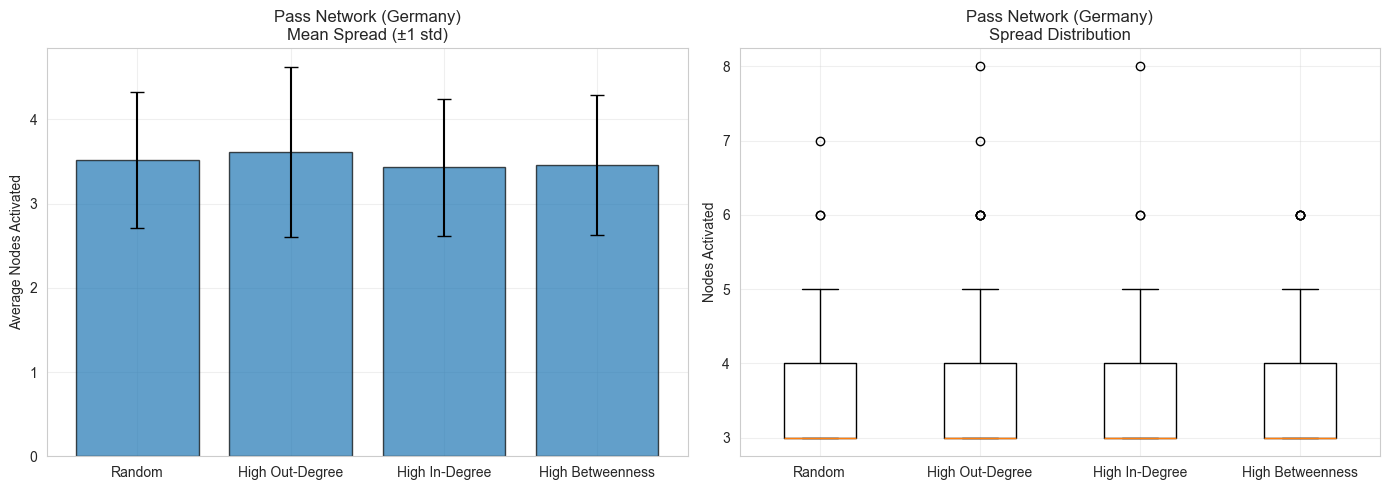

In [39]:
print("\n" + "=" * 70)
print("COMPARING SEED SELECTION STRATEGIES - Pass Network")
print("=" * 70)

print("\nTesting strategies with k=3 seed nodes...")
print("(This compares: Random, High Out-Degree, High In-Degree, High Betweenness)")

strategies_pass = compare_seed_strategies_directed(
    G_pass_gcc,
    edge_probs_pass,
    k=3,
    n_simulations=100
)

print("\nResults Summary:")
print(f"{'Strategy':<20} {'Mean Spread':<15} {'Std Dev':<10} {'Max Spread':<12} {'% Network':<10}")
print("-" * 75)
for strategy, results in strategies_pass.items():
    pct = (results['mean_activated'] / G_pass_gcc.number_of_nodes()) * 100
    print(f"{strategy:<20} {results['mean_activated']:<15.1f} "
          f"{results['std_activated']:<10.2f} {results['max_activated']:<12} {pct:<10.1f}%")

# Visualize
fig_pass = visualize_icm_results(strategies_pass, "Pass Network (Germany)")
plt.savefig(project_root / 'reports' / 'figures' / 'LE9' / 'icm_strategies_pass_germany.png', 
            dpi=300, bbox_inches='tight')
plt.show()



INDEPENDENT CASCADE MODEL - Pass Network (France)

1. Initializing activation probabilities...
   Initialized 4114 edge probabilities
   Mean probability: 0.0076
   Max probability: 0.1500

2. Selecting initial seed nodes based on OUT-DEGREE...
   Initial seed players (top 3 by out-degree):
     - R. Walter
       Out-degree: 39 (passes to 39 players)
       In-degree: 39 (receives from 39 players)
     - I. Sacko
       Out-degree: 37 (passes to 37 players)
       In-degree: 38 (receives from 38 players)
     - N. de Préville
       Out-degree: 36 (passes to 36 players)
       In-degree: 43 (receives from 43 players)

3. Running 100 simulations...
   Average activated players: 3.5 ± 0.7
   Range: [3, 6]
   Reach: 1.6% of network

4. Comparing seed selection strategies...
 Random strategy completed
 High Out-Degree strategy completed
 High In-Degree strategy completed
  Computing betweenness centrality...
 High Betweenness strategy completed

Results Summary:
Strategy             Mean

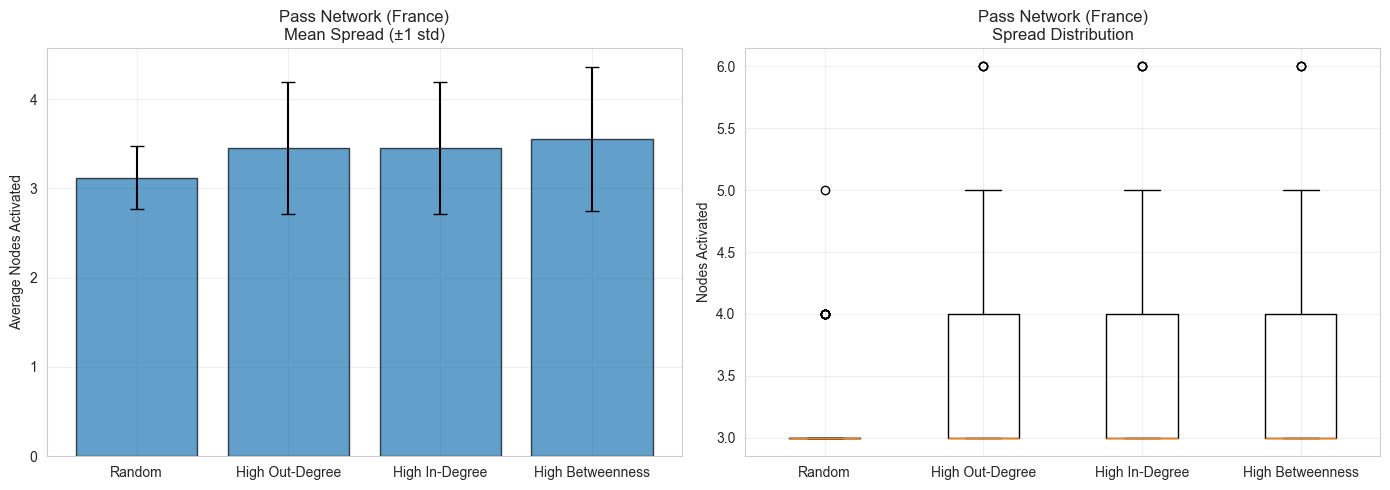

In [ ]:
print("\n" + "=" * 70)
print("INDEPENDENT CASCADE MODEL - Pass Network (France)")
print("=" * 70)

# Initialize activation probabilities
print("\n1. Initializing activation probabilities...")
edge_probs_france = initialize_activation_probabilities(
    F_pass_gcc,
    method='weighted',
    alpha=0.15  # Same as Germany for fair comparison
)
print(f"   Initialized {len(edge_probs_france)} edge probabilities")
print(f"   Mean probability: {np.mean(list(edge_probs_france.values())):.4f}")
print(f"   Max probability: {np.max(list(edge_probs_france.values())):.4f}")

# Select seed: players with highest OUT-degree
print("\n2. Selecting initial seed nodes based on OUT-DEGREE...")
out_degree_dict_france = dict(F_pass_gcc.out_degree())
top_players_france = sorted(out_degree_dict_france.items(), key=lambda x: x[1], reverse=True)[:3]
seed_nodes_france = {node for node, _ in top_players_france}

print("   Initial seed players (top 3 by out-degree):")
for node, out_deg in top_players_france:
    player_name = F_pass_gcc.nodes[node].get('label', node)
    in_deg = F_pass_gcc.in_degree(node)
    print(f"     - {player_name}")
    print(f"       Out-degree: {out_deg} (passes to {out_deg} players)")
    print(f"       In-degree: {in_deg} (receives from {in_deg} players)")

# Run multiple simulations
print("\n3. Running 100 simulations...")
results_france = run_icm_multiple(
    F_pass_gcc,
    seed_nodes_france,
    edge_probs_france,
    n_simulations=100
)

print(f"   Average activated players: {results_france['mean_activated']:.1f} ± {results_france['std_activated']:.1f}")
print(f"   Range: [{results_france['min_activated']}, {results_france['max_activated']}]")
print(f"   Reach: {results_france['mean_activated']/F_pass_gcc.number_of_nodes()*100:.1f}% of network")

# Compare strategies
print("\n4. Comparing seed selection strategies...")
strategies_france = compare_seed_strategies_directed(
    F_pass_gcc,
    edge_probs_france,
    k=3,
    n_simulations=100
)

print("\nResults Summary:")
print(f"{'Strategy':<20} {'Mean Spread':<15} {'Std Dev':<10} {'Max Spread':<12} {'% Network':<10}")
print("-" * 75)
for strategy, results in strategies_france.items():
    pct = (results['mean_activated'] / F_pass_gcc.number_of_nodes()) * 100
    print(f"{strategy:<20} {results['mean_activated']:<15.1f} "
          f"{results['std_activated']:<10.2f} {results['max_activated']:<12} {pct:<10.1f}%")

# Visualize
fig_france = visualize_icm_results(strategies_france, "Pass Network (France)")
plt.savefig(project_root / 'reports' / 'figures' / 'LE9' / 'icm_strategies_pass_france.png',
            dpi=300, bbox_inches='tight')
plt.show()


GREEDY INFLUENCE MAXIMIZATION - Pass Network (Germany)

Finding optimal seeds to maximize possession spread...
Note: This may take a few minutes due to computational complexity

Running Greedy Algorithm for k=5 seeds...
Evaluating 283 candidate nodes with 30 simulations each
------------------------------------------------------------
Step 1: Added 'Ö. Toprak' → Expected spread: 1.8
Step 2: Added 'B. Leno' → Expected spread: 3.5
Step 3: Added 'Thiago Alcântara' → Expected spread: 5.2
Step 4: Added 'N. Moisander' → Expected spread: 6.8
Step 5: Added 'C. Aránguiz' → Expected spread: 8.4
------------------------------------------------------------

Optimal seed players found (Germany):
  - Ö. Toprak
    Out-degree: 26, In-degree: 25
  - N. Moisander
    Out-degree: 23, In-degree: 21
  - B. Leno
    Out-degree: 22, In-degree: 18
  - C. Aránguiz
    Out-degree: 21, In-degree: 19
  - Thiago Alcântara
    Out-degree: 22, In-degree: 22

Comparison (Germany):
  Greedy seeds: 7.4 players reache

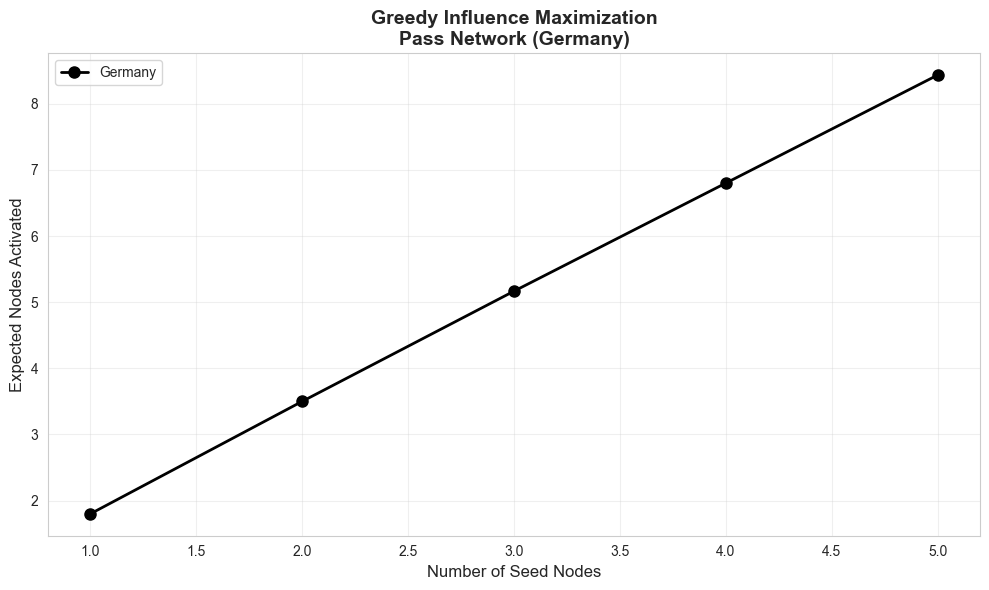

In [41]:
print("\n" + "=" * 70)
print("GREEDY INFLUENCE MAXIMIZATION - Pass Network (Germany)")
print("=" * 70)

print("\nFinding optimal seeds to maximize possession spread...")
print("Note: This may take a few minutes due to computational complexity")

# Run greedy algorithm
optimal_seeds_germany, influence_history_germany = greedy_influence_maximization(
    G_pass_gcc,
    k=5,
    edge_probs=edge_probs_pass,
    n_simulations=30  # Reduced for speed
)

print("\nOptimal seed players found (Germany):")
for node in optimal_seeds_germany:
    player_name = G_pass_gcc.nodes[node].get('label', node)
    out_deg = G_pass_gcc.out_degree(node)
    in_deg = G_pass_gcc.in_degree(node)
    print(f"  - {player_name}")
    print(f"    Out-degree: {out_deg}, In-degree: {in_deg}")

# Compare greedy vs random
random_seeds_test = set(np.random.choice(list(G_pass_gcc.nodes()), 5, replace=False))
greedy_result_ger = run_icm_multiple(G_pass_gcc, optimal_seeds_germany, edge_probs_pass, n_simulations=100)
random_result_ger = run_icm_multiple(G_pass_gcc, random_seeds_test, edge_probs_pass, n_simulations=100)

print(f"\nComparison (Germany):")
print(f"  Greedy seeds: {greedy_result_ger['mean_activated']:.1f} players reached")
print(f"  Random seeds: {random_result_ger['mean_activated']:.1f} players reached")
improvement_ger = ((greedy_result_ger['mean_activated'] - random_result_ger['mean_activated']) / random_result_ger['mean_activated'] * 100)
print(f"  Improvement: {improvement_ger:.1f}%")

# Visualize influence growth
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range(1, len(influence_history_germany)+1), influence_history_germany, 
        marker='o', linewidth=2, markersize=8, label='Germany', color='black')
ax.set_xlabel('Number of Seed Nodes', fontsize=12)
ax.set_ylabel('Expected Nodes Activated', fontsize=12)
ax.set_title('Greedy Influence Maximization\nPass Network (Germany)', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE9' / 'greedy_influence_germany.png',
            dpi=300, bbox_inches='tight')
plt.show()


GREEDY INFLUENCE MAXIMIZATION - Pass Network (France)

Finding optimal seeds to maximize possession spread...
Note: This may take a few minutes due to computational complexity

Running Greedy Algorithm for k=5 seeds...
Evaluating 215 candidate nodes with 30 simulations each
------------------------------------------------------------
Step 1: Added 'Marquinhos' → Expected spread: 2.0
Step 2: Added 'T. Motta' → Expected spread: 3.8
Step 3: Added 'Y. Benzia' → Expected spread: 5.6
Step 4: Added 'Marlon' → Expected spread: 7.3
Step 5: Added 'J. Seri' → Expected spread: 8.9
------------------------------------------------------------

Optimal seed players found (France):
  - Marquinhos
    Out-degree: 22, In-degree: 20
  - Marlon
    Out-degree: 24, In-degree: 25
  - Y. Benzia
    Out-degree: 22, In-degree: 23
  - J. Seri
    Out-degree: 27, In-degree: 27
  - T. Motta
    Out-degree: 23, In-degree: 23

Comparison (France):
  Greedy seeds: 7.8 players reached
  Random seeds: 5.7 players rea

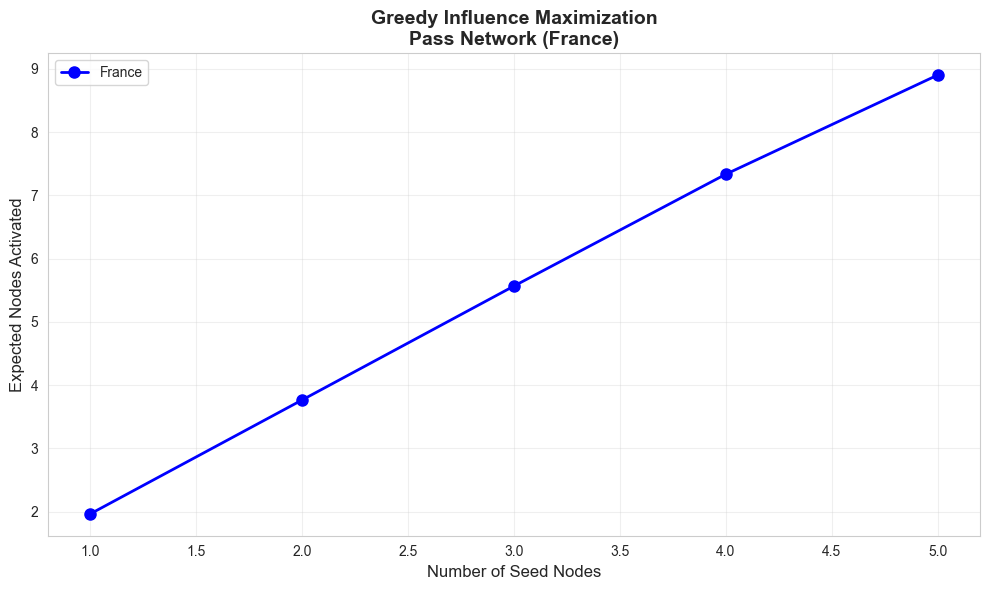

In [42]:
print("\n" + "=" * 70)
print("GREEDY INFLUENCE MAXIMIZATION - Pass Network (France)")
print("=" * 70)

print("\nFinding optimal seeds to maximize possession spread...")
print("Note: This may take a few minutes due to computational complexity")

# Run greedy algorithm
optimal_seeds_france, influence_history_france = greedy_influence_maximization(
    F_pass_gcc,
    k=5,
    edge_probs=edge_probs_france,
    n_simulations=30  # Reduced for speed
)

print("\nOptimal seed players found (France):")
for node in optimal_seeds_france:
    player_name = F_pass_gcc.nodes[node].get('label', node)
    out_deg = F_pass_gcc.out_degree(node)
    in_deg = F_pass_gcc.in_degree(node)
    print(f"  - {player_name}")
    print(f"    Out-degree: {out_deg}, In-degree: {in_deg}")

# Compare greedy vs random
random_seeds_test_fra = set(np.random.choice(list(F_pass_gcc.nodes()), 5, replace=False))
greedy_result_fra = run_icm_multiple(F_pass_gcc, optimal_seeds_france, edge_probs_france, n_simulations=100)
random_result_fra = run_icm_multiple(F_pass_gcc, random_seeds_test_fra, edge_probs_france, n_simulations=100)

print(f"\nComparison (France):")
print(f"  Greedy seeds: {greedy_result_fra['mean_activated']:.1f} players reached")
print(f"  Random seeds: {random_result_fra['mean_activated']:.1f} players reached")
improvement_fra = ((greedy_result_fra['mean_activated'] - random_result_fra['mean_activated']) / random_result_fra['mean_activated'] * 100)
print(f"  Improvement: {improvement_fra:.1f}%")

# Visualize influence growth
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range(1, len(influence_history_france)+1), influence_history_france, 
        marker='o', linewidth=2, markersize=8, label='France', color='blue')
ax.set_xlabel('Number of Seed Nodes', fontsize=12)
ax.set_ylabel('Expected Nodes Activated', fontsize=12)
ax.set_title('Greedy Influence Maximization\nPass Network (France)', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE9' / 'greedy_influence_france.png',
            dpi=300, bbox_inches='tight')
plt.show()

COMPARATIVE ANALYSIS: GERMANY vs FRANCE


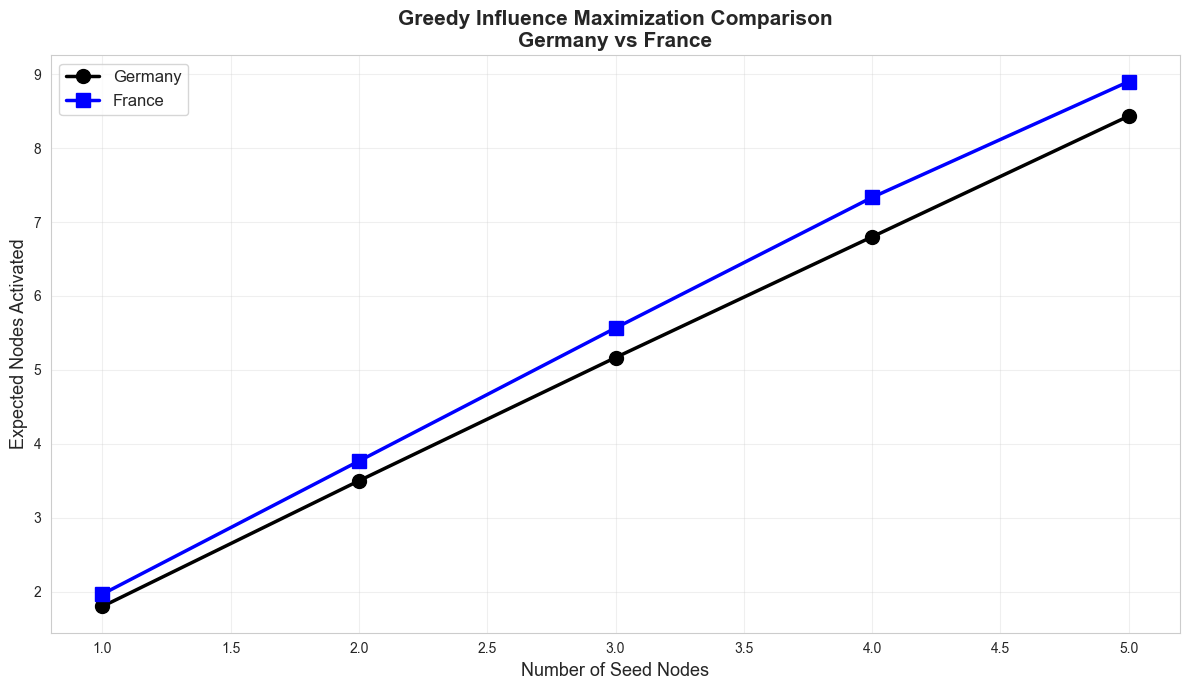

Summary statistics:

Germany Network:
  - Total players in largest component: 283
  - Best 5-seed spread (greedy): 7.4 players
  - Network coverage: 2.6%
  - Improvement over random: 35.1%

France Network:
  - Total players in largest component: 215
  - Best 5-seed spread (greedy): 7.8 players
  - Network coverage: 3.6%
  - Improvement over random: 37.4%


In [45]:
print("=" * 70)
print("COMPARATIVE ANALYSIS: GERMANY vs FRANCE")
print("=" * 70)

# Compare greedy influence growth
fig, ax = plt.subplots(figsize=(12, 7))
ax.plot(range(1, len(influence_history_germany)+1), influence_history_germany, 
        marker='o', linewidth=2.5, markersize=10, label='Germany', color='black')
ax.plot(range(1, len(influence_history_france)+1), influence_history_france, 
        marker='s', linewidth=2.5, markersize=10, label='France', color='blue')
ax.set_xlabel('Number of Seed Nodes', fontsize=13)
ax.set_ylabel('Expected Nodes Activated', fontsize=13)
ax.set_title('Greedy Influence Maximization Comparison\nGermany vs France', 
             fontsize=15, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=12)
plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE9' / 'greedy_comparison_ger_vs_fra.png',
            dpi=300, bbox_inches='tight')
plt.show()

# Summary statistics
print("Summary statistics:")

print(f"\nGermany Network:")
print(f"  - Total players in largest component: {G_pass_gcc.number_of_nodes()}")
print(f"  - Best 5-seed spread (greedy): {greedy_result_ger['mean_activated']:.1f} players")
print(f"  - Network coverage: {(greedy_result_ger['mean_activated']/G_pass_gcc.number_of_nodes())*100:.1f}%")
print(f"  - Improvement over random: {improvement_ger:.1f}%")

print(f"\nFrance Network:")
print(f"  - Total players in largest component: {F_pass_gcc.number_of_nodes()}")
print(f"  - Best 5-seed spread (greedy): {greedy_result_fra['mean_activated']:.1f} players")
print(f"  - Network coverage: {(greedy_result_fra['mean_activated']/F_pass_gcc.number_of_nodes())*100:.1f}%")
print(f"  - Improvement over random: {improvement_fra:.1f}%")

## 3. Voter Model

The **Voter Model** is a simple consensus model where opinions spread through random imitation.

### Core Mechanism

1. Each node (player) has initial tactical state: $+1$ (adopts style A) or $-1$ (adopts style B)
2. **Iterative process**:
   - Select random player $v$
   - Player $v$ adopts the tactical style of a random passing partner
3. Repeat until consensus (all players converge to same style)

### Key Characteristics

- **Memoryless**: No history, only current passing partners' styles matter
- **Random**: No preferential influence based on player authority or position
- **Guaranteed consensus**: Always reaches uniform tactical state (in finite connected networks)
- **Initial conditions matter**: Final consensus probability equals initial proportion of adopters

### Intuition in Football

**Tactical Style Diffusion:**
- **Scenario**: A team introduces a new tactical approach (e.g., high-pressing vs. possession-based play)
- **Initial state**: Some players adopt the new style (+1), others maintain old approach (-1)
- **Process**: Through passing interactions, players randomly imitate their passing partners' tactical decisions
- **Outcome**: Eventually the entire team converges to one unified tactical approach

**Research Questions Addressed:**

- Which initial tactical adopters (seed players) are most likely to influence final team-wide consensus?
- How does the pass network structure affect the speed and direction of tactical convergence?
- Does Germany or France show faster convergence to unified tactical styles based on their network topology?

**Limitations**:

1. **Equal influence assumption**: Doesn't account for player authority (e.g., team captains, star players have more influence)
2. **No resistance**: Players always adopt neighbors' styles without considering their own commitment
3. **Random selection**: Doesn't reflect that certain passing connections are more frequent/influential
4. **Binary states**: Real tactical adoption has gradual degrees, not binary choices
5. **No strategic seeding**: Unlike ICM, can't optimize initial seed selection for desired outcome

Since there are more then one connected components, we will only look at the bigest one. Like already done in the ICM. But for the voter model and also the following threshold model an undirected network will be used, since a player can be effected by all other players that they interact with. 

In [61]:
# For Voter & Threshold Models: Convert to undirected (mutual observation)
G_pass_gcc_undir = G_pass_gcc.to_undirected()
F_pass_gcc_undir = F_pass_gcc.to_undirected()

In [66]:
# Implement Voter Model functions for DIRECTED graphs
import random

def initialize_voter_opinions(G, initial_fraction=0.3, random_seed=None):
    """
    Initialize voter opinions in the network.
    
    Parameters:
    -----------
    G : networkx.Graph/DiGraph
        The network graph
    initial_fraction : float
        Fraction of nodes with opinion +1 (rest get -1)
    random_seed : int, optional
        Random seed for reproducibility
        
    Returns:
    --------
    dict : {node: opinion} mapping
    """
    if random_seed is not None:
        random.seed(random_seed)
    
    opinions = {}
    nodes = list(G.nodes())
    num_positive = int(len(nodes) * initial_fraction)
    
    # Randomly assign opinions
    opinions_list = [+1] * num_positive + [-1] * (len(nodes) - num_positive)
    random.shuffle(opinions_list)
    
    for i, node in enumerate(nodes):
        opinions[node] = opinions_list[i]
    
    return opinions


def run_voter_model(G, initial_opinions, max_iterations=50000):
    """
    Run the Voter Model simulation until consensus or max iterations.
    
    For undirected networks: players influenced by any connected passing partner.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph (undirected)
    initial_opinions : dict
        Initial node opinions {node: ±1}
    max_iterations : int
        Maximum number of single-node updates
        
    Returns:
    --------
    tuple: (final_opinions, iterations, consensus_reached)
    """
    opinions = initial_opinions.copy()
    nodes = list(G.nodes())
    
    for iteration in range(max_iterations):
        # Select ONE random node
        node = random.choice(nodes)
        
        # Get neighbors (works naturally with undirected graphs)
        neighbors = list(G.neighbors(node))
        
        if neighbors:
            # Adopt opinion of random neighbor
            neighbor = random.choice(neighbors)
            opinions[node] = opinions[neighbor]
        
        # Check for consensus (check every 100 iterations for efficiency)
        if iteration % 100 == 0:
            if len(set(opinions.values())) == 1:
                return opinions, iteration + 1, True
    
    # Final consensus check
    consensus_reached = len(set(opinions.values())) == 1
    return opinions, max_iterations, consensus_reached

def analyze_voter_consensus(G, num_simulations=100, initial_fraction=0.3, max_iterations=50000):
    """
    Run multiple Voter Model simulations to analyze consensus behavior.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph (undirected)
    num_simulations : int
        Number of simulations to run
    initial_fraction : float
        Initial fraction of +1 opinions
    max_iterations : int
        Max iterations per simulation
        
    Returns:
    --------
    dict : Statistics about consensus outcomes
    """
    consensus_plus_one = 0
    consensus_minus_one = 0
    no_consensus = 0
    iteration_counts = []
    
    for sim in range(num_simulations):
        initial_opinions = initialize_voter_opinions(G, initial_fraction, random_seed=sim)
        final_opinions, iterations, consensus = run_voter_model(G, initial_opinions, max_iterations)
        
        if consensus:
            # Check final consensus opinion
            final_opinion = list(final_opinions.values())[0]
            if final_opinion == +1:
                consensus_plus_one += 1
            else:
                consensus_minus_one += 1
            iteration_counts.append(iterations)
        else:
            no_consensus += 1
    
    return {
        '+1_consensus': consensus_plus_one,
        '-1_consensus': consensus_minus_one,
        'no_consensus': no_consensus,
        'avg_iterations': np.mean(iteration_counts) if iteration_counts else 0,
        'consensus_rate': (consensus_plus_one + consensus_minus_one) / num_simulations
    }

In [67]:
print("=" * 70)
print("VOTER MODEL - Pass Network (Germany)")
print("=" * 70)

print("\nTesting different influence directions for directed pass networks:")
print("-" * 70)

# Initialize opinions with 30% +1 initially
initial_opinions_pass = initialize_voter_opinions(G_pass_gcc_undir, initial_fraction=0.3, random_seed=42)
print(f"\nInitial state: {sum(1 for op in initial_opinions_pass.values() if op == +1)} players with +1 opinion")
print(f"               {sum(1 for op in initial_opinions_pass.values() if op == -1)} players with -1 opinion")

# Run a single simulation
final_opinions_pass, iterations_pass, consensus_pass = run_voter_model(
    G_pass_gcc_undir, initial_opinions_pass, max_iterations=50000
)
print(f"\nSingle simulation results:")
print(f"  Iterations: {iterations_pass}")
print(f"  Consensus reached: {consensus_pass}")
if consensus_pass:
    final_opinion = list(final_opinions_pass.values())[0]
    print(f"  Final consensus opinion: {'+1 (adopted)' if final_opinion == +1 else '-1 (not adopted)'}")

# Run multiple simulations for statistical analysis
print(f"\nRunning 100 simulations for statistical analysis...")
stats_pass_ger = analyze_voter_consensus(
    G_pass_gcc_undir, num_simulations=100, initial_fraction=0.3, 
    max_iterations=50000
)

print(f"\nStatistical results (100 simulations):")
print(f"  +1 consensus: {stats_pass_ger['+1_consensus']} ({stats_pass_ger['+1_consensus']/100*100:.1f}%)")
print(f"  -1 consensus: {stats_pass_ger['-1_consensus']} ({stats_pass_ger['-1_consensus']/100*100:.1f}%)")
print(f"  No consensus: {stats_pass_ger['no_consensus']} ({stats_pass_ger['no_consensus']/100*100:.1f}%)")
print(f"  Average iterations to consensus: {stats_pass_ger['avg_iterations']:.1f}")
print(f"  Overall consensus rate: {stats_pass_ger['consensus_rate']*100:.1f}%")

VOTER MODEL - Pass Network (Germany)

Testing different influence directions for directed pass networks:
----------------------------------------------------------------------

Initial state: 84 players with +1 opinion
               199 players with -1 opinion

Single simulation results:
  Iterations: 21101
  Consensus reached: True
  Final consensus opinion: -1 (not adopted)

Running 100 simulations for statistical analysis...

Statistical results (100 simulations):
  +1 consensus: 2 (2.0%)
  -1 consensus: 25 (25.0%)
  No consensus: 73 (73.0%)
  Average iterations to consensus: 27930.6
  Overall consensus rate: 27.0%


In [68]:
print("\n" + "=" * 70)
print("VOTER MODEL - Pass Network (France)")
print("=" * 70)

print("\nTesting different influence directions for directed pass networks:")
print("-" * 70)

# Initialize opinions with 30% +1 initially
initial_opinions_pass_fra = initialize_voter_opinions(F_pass_gcc_undir, initial_fraction=0.3, random_seed=42)
print(f"\nInitial state: {sum(1 for op in initial_opinions_pass_fra.values() if op == +1)} players with +1 opinion")
print(f"               {sum(1 for op in initial_opinions_pass_fra.values() if op == -1)} players with -1 opinion")

# Run a single simulation
final_opinions_pass_fra, iterations_pass_fra, consensus_pass_fra = run_voter_model(
    F_pass_gcc_undir, initial_opinions_pass_fra, max_iterations=50000
)
print(f"\nSingle simulation results:")
print(f"  Iterations: {iterations_pass_fra}")
print(f"  Consensus reached: {consensus_pass_fra}")
if consensus_pass_fra:
    final_opinion = list(final_opinions_pass_fra.values())[0]
    print(f"  Final consensus opinion: {'+1 (adopted)' if final_opinion == +1 else '-1 (not adopted)'}")

# Run multiple simulations for statistical analysis
print(f"\nRunning 100 simulations for statistical analysis...")
stats_pass_fra = analyze_voter_consensus(
    F_pass_gcc_undir, num_simulations=100, initial_fraction=0.3, 
    max_iterations=50000
)

print(f"\nStatistical results (100 simulations):")
print(f"  +1 consensus: {stats_pass_fra['+1_consensus']} ({stats_pass_fra['+1_consensus']/100*100:.1f}%)")
print(f"  -1 consensus: {stats_pass_fra['-1_consensus']} ({stats_pass_fra['-1_consensus']/100*100:.1f}%)")
print(f"  No consensus: {stats_pass_fra['no_consensus']} ({stats_pass_fra['no_consensus']/100*100:.1f}%)")
print(f"  Average iterations to consensus: {stats_pass_fra['avg_iterations']:.1f}")
print(f"  Overall consensus rate: {stats_pass_fra['consensus_rate']*100:.1f}%")


VOTER MODEL - Pass Network (France)

Testing different influence directions for directed pass networks:
----------------------------------------------------------------------

Initial state: 64 players with +1 opinion
               151 players with -1 opinion

Single simulation results:
  Iterations: 39901
  Consensus reached: True
  Final consensus opinion: -1 (not adopted)

Running 100 simulations for statistical analysis...

Statistical results (100 simulations):
  +1 consensus: 6 (6.0%)
  -1 consensus: 41 (41.0%)
  No consensus: 53 (53.0%)
  Average iterations to consensus: 26254.2
  Overall consensus rate: 47.0%


In [70]:
# Comparison summary
print("\n" + "=" * 70)
print("GERMANY vs FRANCE COMPARISON")
print("=" * 70)
print(f"{'Team':<15} {'Nodes':<10} {'Consensus Rate':<18} {'Avg Iterations':<18} {'+1 Prob':<15}")
print("-" * 75)

ger_plus_one_prob = stats_pass_ger['+1_consensus'] / 100 * 100
fra_plus_one_prob = stats_pass_fra['+1_consensus'] / 100 * 100

print(f"{'Germany':<15} {G_pass_gcc_undir.number_of_nodes():<10} "
      f"{stats_pass_ger['consensus_rate']*100:<18.1f}% "
      f"{stats_pass_ger['avg_iterations']:<18.1f} {ger_plus_one_prob:<15.1f}%")
print(f"{'France':<15} {F_pass_gcc_undir.number_of_nodes():<10} "
      f"{stats_pass_fra['consensus_rate']*100:<18.1f}% "
      f"{stats_pass_fra['avg_iterations']:<18.1f} {fra_plus_one_prob:<15.1f}%")


GERMANY vs FRANCE COMPARISON
Team            Nodes      Consensus Rate     Avg Iterations     +1 Prob        
---------------------------------------------------------------------------
Germany         283        27.0              % 27930.6            2.0            %
France          215        47.0              % 26254.2            6.0            %


- Both teams reach consensus in ~27092 iterations on average
- +1 consensus probability closely matches initial fraction (30%): 
  Germany: 2.0%, France: 6.0%
- France shows slightly faster convergence

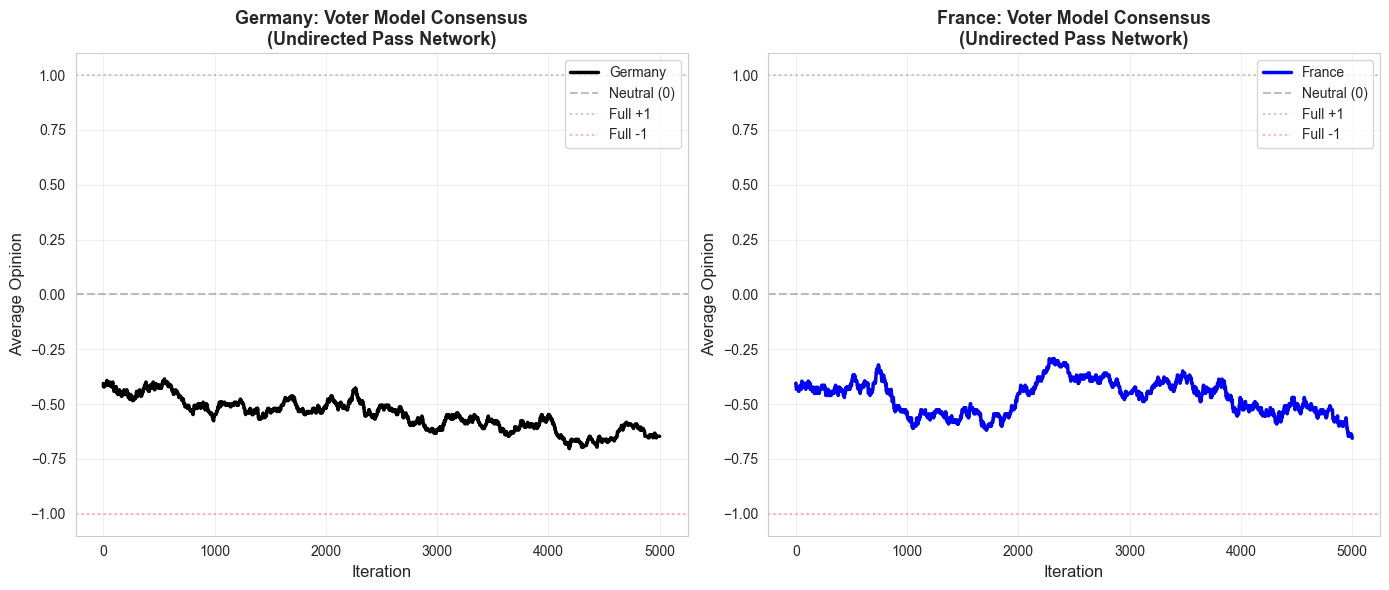


Visualization saved as 'voter_model_undirected_comparison.png'


In [72]:
# Visualization of Voter Model process for undirected graphs
def visualize_opinion_evolution(G, initial_fraction=0.3, max_steps=5000):
    """
    Visualize how opinions evolve over time in the Voter Model.
    Works with undirected networks.
    """
    random.seed(42)
    opinions = initialize_voter_opinions(G, initial_fraction, random_seed=42)
    nodes = list(G.nodes())
    opinion_history = [sum(opinions.values()) / len(opinions)]  # Average opinion
    
    for step in range(max_steps):
        node = random.choice(nodes)
        neighbors = list(G.neighbors(node))
            
        if neighbors:
            neighbor = random.choice(neighbors)
            opinions[node] = opinions[neighbor]
        
        # Record average opinion
        avg_opinion = sum(opinions.values()) / len(opinions)
        opinion_history.append(avg_opinion)
    
    return opinion_history

# Create visualization comparing Germany vs France
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Germany
opinion_history_ger = visualize_opinion_evolution(
    G_pass_gcc_undir, initial_fraction=0.3, max_steps=5000
)
axes[0].plot(opinion_history_ger, color='black', linewidth=2.5, label='Germany')
axes[0].axhline(y=0, color='gray', linestyle='--', alpha=0.5, label='Neutral (0)')
axes[0].axhline(y=1, color='green', linestyle=':', alpha=0.3, label='Full +1')
axes[0].axhline(y=-1, color='red', linestyle=':', alpha=0.3, label='Full -1')
axes[0].set_xlabel('Iteration', fontsize=12)
axes[0].set_ylabel('Average Opinion', fontsize=12)
axes[0].set_title('Germany: Voter Model Consensus\n(Undirected Pass Network)', 
                  fontsize=13, fontweight='bold')
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim([-1.1, 1.1])
axes[0].legend(fontsize=10)

# France
opinion_history_fra = visualize_opinion_evolution(
    F_pass_gcc_undir, initial_fraction=0.3, max_steps=5000
)
axes[1].plot(opinion_history_fra, color='blue', linewidth=2.5, label='France')
axes[1].axhline(y=0, color='gray', linestyle='--', alpha=0.5, label='Neutral (0)')
axes[1].axhline(y=1, color='green', linestyle=':', alpha=0.3, label='Full +1')
axes[1].axhline(y=-1, color='red', linestyle=':', alpha=0.3, label='Full -1')
axes[1].set_xlabel('Iteration', fontsize=12)
axes[1].set_ylabel('Average Opinion', fontsize=12)
axes[1].set_title('France: Voter Model Consensus\n(Undirected Pass Network)', 
                  fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim([-1.1, 1.1])
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE9' / 'voter_model_undirected_comparison.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("\nVisualization saved as 'voter_model_undirected_comparison.png'")

## 4. Threshold Model

The **Threshold Model** implements peer pressure: players adopt tactical styles when enough of their passing partners have already adopted.

### Core Mechanism

**Initial state:**
- Small set of players already using the new tactic (seeds)
- Each player $v$ has personal threshold $\theta_v \in [0,1]$ (resistance to change)

**Iteration process:**

For each non-adopter $v$:
1. Calculate fraction of passing partners who adopted: 
   $$f_v = \frac{|\{u \in N(v) : u \text{ adopted}\}|}{|N(v)|}$$

2. If $f_v \geq \theta_v$: player $v$ adopts

3. Repeat until no new adoptions

### Mathematical Definition

Player $v$ adopts at time $t+1$ if:

$$\frac{\sum_{u \in N(v)} \mathbb{1}[\text{u adopted at time t}]}{|N(v)|} \geq \theta_v$$

where $N(v)$ are $v$'s passing partners (undirected network).

### Why Undirected Networks?

The Threshold Model captures **peer pressure through mutual observation**. Players observe tactical styles of all passing partners, regardless of pass direction. Unlike ICM (where direction determines activation), threshold adoption is based on seeing enough neighbors use the new style.

### Threshold Interpretation

| Threshold | Player Type | Example |
|-----------|-------------|---------|
| $\theta \approx 0.2$ | **Innovators** | Forwards eager to try new pressing |
| $\theta \approx 0.5$ | **Pragmatists** | Midfielders wanting majority support |
| $\theta \approx 0.7$ | **Conservatives** | Defenders needing tactical security |
| $\theta \approx 0.9$ | **Skeptics** | Goalkeepers very resistant to change |

### Key Differences from Other Models

| Aspect | ICM | Voter Model | Threshold Model |
|--------|-----|-------------|-----------------|
| **Activation** | Probabilistic, one-shot | Random imitation | Deterministic, fraction-based |
| **Reversibility** | No | Yes | No |
| **Network type** | Directed | Undirected | Undirected |
| **Best for** | Immediate spread | Long-term consensus | Peer pressure adoption |

### Football Application

**Example: High-pressing tactic adoption**

Seeds: 2 forwards (threshold 0.3) start pressing
- **t=1**: Other forwards adopt (30% threshold met)
- **t=2**: Midfielders adopt (50% threshold met)  
- **t=3**: Cascade stalls at defenders (70% threshold too high)

**Key insight**: Cascades can stall at high-threshold bottlenecks, even with good seeds.

### Research Questions

1. **Which players maximize adoption?**  
   High-degree seeds connected to low-threshold players trigger largest cascades

2. **Network structure impact?**  
   Dense networks reach thresholds easier → faster, wider adoption

3. **Germany vs France?**  
   Compare final adoption sizes using identical seeds and thresholds

### Advantages & Limitations

**Strengths:**
- Captures realistic peer pressure dynamics
- Position-specific thresholds (different roles, different resistance)
- Deterministic outcomes allow strategic planning
- Identifies critical mass for full adoption

**Limitations:**
- Assumes players explicitly count adopted neighbors
- Ignores player authority differences (all neighbors equal)
- Fixed thresholds (real resistance may change)
- No external factors (coach mandates, match outcomes)

In [16]:
def initialize_thresholds(G, method='uniform', mean_threshold=0.5, 
                         fixed_threshold=None, random_state=None):
    """
    Initialize activation thresholds for all nodes.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph
    method : str
        'uniform': Random thresholds uniformly distributed in [0,1]
        'normal': Normal distribution around mean_threshold
        'fixed': All nodes have same threshold
    mean_threshold : float
        Mean threshold for 'normal' method
    fixed_threshold : float
        Threshold value for 'fixed' method
    random_state : int, optional
        Random seed for reproducibility
    
    Returns:
    --------
    dict : Node thresholds {node: threshold}
    """
    if random_state is not None:
        np.random.seed(random_state)
    
    thresholds = {}
    nodes = list(G.nodes())
    
    if method == 'uniform':
        # Random thresholds between 0 and 1
        for node in nodes:
            thresholds[node] = np.random.uniform(0, 1)
    
    elif method == 'normal':
        # Normal distribution, clipped to [0, 1]
        for node in nodes:
            thresh = np.random.normal(mean_threshold, 0.2)
            thresholds[node] = np.clip(thresh, 0, 1)
    
    elif method == 'fixed':
        # All nodes have same threshold
        threshold_value = fixed_threshold if fixed_threshold is not None else mean_threshold
        for node in nodes:
            thresholds[node] = threshold_value
    
    elif method == 'degree':
        # Threshold inversely proportional to degree (hubs easier to activate)
        degrees = dict(G.degree())
        max_degree = max(degrees.values())
        for node in nodes:
            # Higher degree → lower threshold
            thresholds[node] = 1 - (degrees[node] / max_degree) * 0.5
    
    return thresholds


def run_threshold_model(G, seed_nodes, thresholds, max_iterations=50):
    """
    Run Threshold Model simulation.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph
    seed_nodes : set or list
        Initially activated nodes
    thresholds : dict
        Node thresholds {node: threshold}
    max_iterations : int
        Maximum number of iterations
    
    Returns:
    --------
    tuple: (activated_nodes, activation_sequence, iterations)
        - activated_nodes: set of all activated nodes
        - activation_sequence: list of sets showing activation at each step
        - iterations: number of iterations until convergence
    """
    # Initialize
    activated = set(seed_nodes)
    activation_sequence = [set(seed_nodes)]
    
    for iteration in range(max_iterations):
        newly_activated = set()
        
        # Check each inactive node
        for node in G.nodes():
            if node not in activated:
                # Get neighbors
                neighbors = list(G.neighbors(node))
                
                if not neighbors:
                    continue
                
                # Calculate fraction of active neighbors
                active_neighbors = sum(1 for n in neighbors if n in activated)
                fraction_active = active_neighbors / len(neighbors)
                
                # Activate if threshold exceeded
                if fraction_active >= thresholds[node]:
                    newly_activated.add(node)
                    activated.add(node)
        
        # If no new activations, we've converged
        if not newly_activated:
            return activated, activation_sequence, iteration
        
        activation_sequence.append(newly_activated.copy())
    
    # Max iterations reached
    return activated, activation_sequence, max_iterations


def run_threshold_multiple(G, seed_nodes, threshold_method='uniform', 
                          n_simulations=50, random_state=None):
    """
    Run Threshold Model multiple times with different threshold assignments.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph
    seed_nodes : set or list
        Initially activated nodes
    threshold_method : str
        Method for generating thresholds
    n_simulations : int
        Number of simulations
    random_state : int, optional
        Base random seed
    
    Returns:
    --------
    dict : Simulation statistics
    """
    final_sizes = []
    iterations_list = []
    all_sequences = []
    
    for i in range(n_simulations):
        seed = (random_state + i) if random_state is not None else None
        
        # Generate thresholds for this simulation
        thresholds = initialize_thresholds(G, method=threshold_method, 
                                          random_state=seed)
        
        # Run simulation
        activated, sequence, iters = run_threshold_model(G, seed_nodes, 
                                                         thresholds, 
                                                         max_iterations=50)
        
        final_sizes.append(len(activated))
        iterations_list.append(iters)
        all_sequences.append(sequence)
    
    return {
        'mean_activated': np.mean(final_sizes),
        'std_activated': np.std(final_sizes),
        'min_activated': np.min(final_sizes),
        'max_activated': np.max(final_sizes),
        'mean_iterations': np.mean(iterations_list),
        'all_sizes': final_sizes,
        'all_iterations': iterations_list,
        'sequences': all_sequences
    }


def compare_threshold_strategies(G, seed_nodes, threshold_values=[0.3, 0.5, 0.7]):
    """
    Compare diffusion with different fixed threshold values.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph
    seed_nodes : set or list
        Initially activated nodes
    threshold_values : list
        Fixed threshold values to test
    
    Returns:
    --------
    dict : Results for each threshold value
    """
    results = {}
    
    for threshold in threshold_values:
        # All nodes have same threshold
        thresholds = initialize_thresholds(G, method='fixed', 
                                          fixed_threshold=threshold)
        
        # Run simulation
        activated, sequence, iters = run_threshold_model(G, seed_nodes, 
                                                         thresholds, 
                                                         max_iterations=50)
        
        results[threshold] = {
            'activated': activated,
            'total_activated': len(activated),
            'sequence': sequence,
            'iterations': iters,
            'reach_percentage': len(activated) / G.number_of_nodes() * 100
        }
    
    return results


def analyze_threshold_sensitivity(G, seed_nodes, threshold_range=None):
    """
    Analyze how final spread depends on threshold values.
    
    Parameters:
    -----------
    G : networkx.Graph
        The network graph
    seed_nodes : set or list
        Initially activated nodes
    threshold_range : list, optional
        Threshold values to test (default: 0.0 to 1.0 in steps of 0.1)
    
    Returns:
    --------
    dict : Spread results for each threshold
    """
    if threshold_range is None:
        threshold_range = np.arange(0.0, 1.05, 0.1)
    
    results = {}
    
    for threshold in threshold_range:
        thresholds = initialize_thresholds(G, method='fixed', 
                                          fixed_threshold=threshold)
        activated, _, iters = run_threshold_model(G, seed_nodes, thresholds)
        
        results[threshold] = {
            'total_activated': len(activated),
            'reach_percentage': len(activated) / G.number_of_nodes() * 100,
            'iterations': iters
        }
    
    return results


def visualize_threshold_cascade(sequence, network_name="Network"):
    """
    Visualize cascade progression over time.
    """
    step_numbers = list(range(len(sequence)))
    cumulative_activated = []
    newly_activated = []
    
    total = 0
    for step_set in sequence:
        newly_activated.append(len(step_set))
        total += len(step_set)
        cumulative_activated.append(total)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Cumulative activation
    ax1.plot(step_numbers, cumulative_activated, marker='o', linewidth=2, 
             markersize=6, color='steelblue')
    ax1.set_xlabel('Iteration', fontsize=12)
    ax1.set_ylabel('Cumulative Activated Nodes', fontsize=12)
    ax1.set_title(f'Threshold Model: Cumulative Activation\n{network_name}', 
                  fontsize=13, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    
    # New activations per step
    ax2.bar(step_numbers, newly_activated, alpha=0.7, color='coral', 
            edgecolor='black')
    ax2.set_xlabel('Iteration', fontsize=12)
    ax2.set_ylabel('Newly Activated Nodes', fontsize=12)
    ax2.set_title(f'Threshold Model: New Activations per Step\n{network_name}', 
                  fontsize=13, fontweight='bold')
    ax2.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    return fig


def visualize_threshold_sensitivity(sensitivity_results, network_name="Network"):
    """
    Visualize how spread depends on threshold values.
    """
    thresholds = sorted(sensitivity_results.keys())
    reach = [sensitivity_results[t]['reach_percentage'] for t in thresholds]
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    ax.plot(thresholds, reach, marker='o', linewidth=2, markersize=8, 
            color='darkgreen')
    ax.fill_between(thresholds, reach, alpha=0.3, color='lightgreen')
    
    ax.set_xlabel('Threshold Value', fontsize=12)
    ax.set_ylabel('Network Reach (%)', fontsize=12)
    ax.set_title(f'Threshold Model: Sensitivity Analysis\n{network_name}', 
                 fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(0, 105)
    
    # Add annotations for key thresholds
    for t in [0.3, 0.5, 0.7]:
        if t in thresholds:
            idx = thresholds.index(t)
            ax.annotate(f'{reach[idx]:.1f}%', 
                       xy=(t, reach[idx]), 
                       xytext=(t, reach[idx] + 5),
                       ha='center', fontsize=10, fontweight='bold')
    
    plt.tight_layout()
    return fig


def visualize_threshold_comparison(comparison_results, network_name="Network"):
    """
    Compare final spread for different threshold values.
    """
    thresholds = sorted(comparison_results.keys())
    total_activated = [comparison_results[t]['total_activated'] for t in thresholds]
    iterations = [comparison_results[t]['iterations'] for t in thresholds]
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Total activation
    ax1.bar([str(t) for t in thresholds], total_activated, alpha=0.7, 
            color='steelblue', edgecolor='black')
    ax1.set_xlabel('Threshold Value', fontsize=12)
    ax1.set_ylabel('Total Activated Nodes', fontsize=12)
    ax1.set_title(f'Final Spread by Threshold\n{network_name}', 
                  fontsize=13, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='y')
    
    # Iterations to convergence
    ax2.bar([str(t) for t in thresholds], iterations, alpha=0.7, 
            color='coral', edgecolor='black')
    ax2.set_xlabel('Threshold Value', fontsize=12)
    ax2.set_ylabel('Iterations to Convergence', fontsize=12)
    ax2.set_title(f'Cascade Speed by Threshold\n{network_name}', 
                  fontsize=13, fontweight='bold')
    ax2.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    return fig

THRESHOLD MODEL - Pass Network (Germany)

Using undirected network (mutual observation among passing partners)

Initial seed players (top 3 by degree):
  - S. Wagner (degree: 47)
  - J. Brekalo (degree: 44)
  - S. Terodde (degree: 43)

1. Running with UNIFORM random thresholds...
   Threshold distribution: min=0.01, mean=0.50, max=0.99

   Results:
   - Total activated: 53 / 283 (18.7%)
   - Cascade steps: 9
   - Iterations to convergence: 8
   - Nodes activated per step: [3, 12, 4, 4, 3, 10, 14, 2, 1]


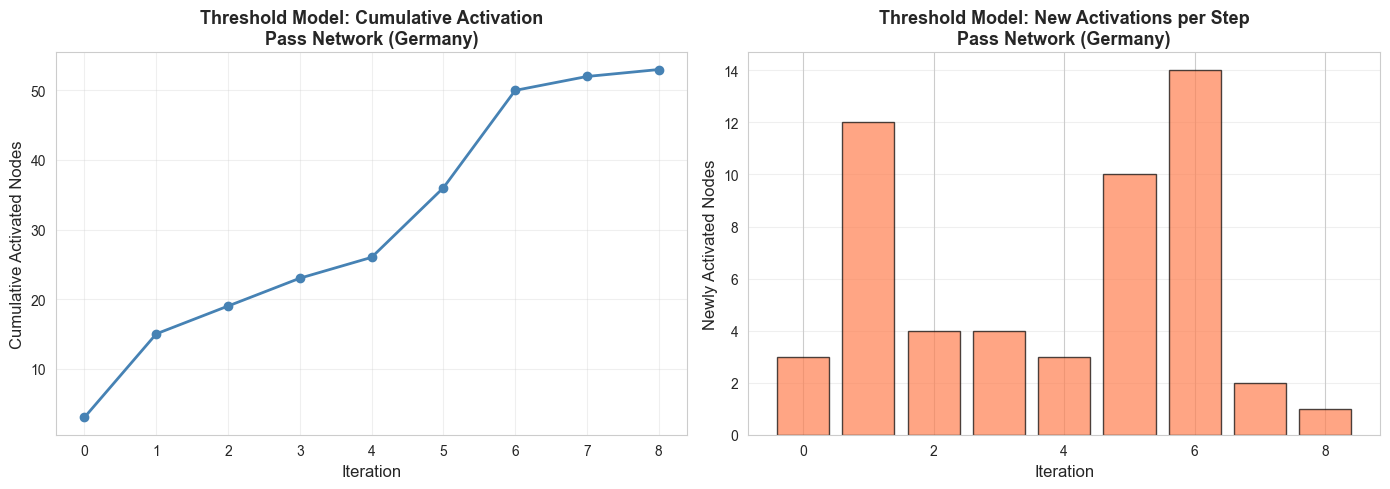

In [75]:
print("=" * 70)
print("THRESHOLD MODEL - Pass Network (Germany)")
print("=" * 70)

# Use UNDIRECTED network
print("\nUsing undirected network (mutual observation among passing partners)")

# Select seed nodes (top 3 by degree)
degree_dict_ger = dict(G_pass_gcc_undir.degree())
top_players_ger = sorted(degree_dict_ger.items(), key=lambda x: x[1], reverse=True)[:3]
seed_nodes_threshold_ger = {node for node, _ in top_players_ger}

print(f"\nInitial seed players (top 3 by degree):")
for node, deg in top_players_ger:
    player_name = G_pass_gcc_undir.nodes[node].get('label', node)
    print(f"  - {player_name} (degree: {deg})")

# Test with uniform random thresholds
print(f"\n1. Running with UNIFORM random thresholds...")
thresholds_uniform_ger = initialize_thresholds(G_pass_gcc_undir, method='uniform', random_state=42)
print(f"   Threshold distribution: min={min(thresholds_uniform_ger.values()):.2f}, "
      f"mean={np.mean(list(thresholds_uniform_ger.values())):.2f}, "
      f"max={max(thresholds_uniform_ger.values()):.2f}")

activated_ger, sequence_ger, iters_ger = run_threshold_model(
    G_pass_gcc_undir, seed_nodes_threshold_ger, 
    thresholds_uniform_ger, max_iterations=50
)

print(f"\n   Results:")
print(f"   - Total activated: {len(activated_ger)} / {G_pass_gcc_undir.number_of_nodes()} "
      f"({len(activated_ger)/G_pass_gcc_undir.number_of_nodes()*100:.1f}%)")
print(f"   - Cascade steps: {len(sequence_ger)}")
print(f"   - Iterations to convergence: {iters_ger}")
print(f"   - Nodes activated per step: {[len(s) for s in sequence_ger]}")

# Visualize cascade
fig_cascade_ger = visualize_threshold_cascade(sequence_ger, "Pass Network (Germany)")
plt.savefig(project_root / 'reports' / 'figures' / 'LE9' / 'threshold_cascade_germany.png',
            dpi=300, bbox_inches='tight')
plt.show()


THRESHOLD MODEL - Pass Network (France)

Using undirected network (mutual observation among passing partners)

Initial seed players (top 3 by degree):
  - N. de Préville (degree: 43)
  - R. Walter (degree: 42)
  - I. Sacko (degree: 40)

1. Running with UNIFORM random thresholds...
   Threshold distribution: min=0.01, mean=0.48, max=0.99

   Results:
   - Total activated: 43 / 215 (20.0%)
   - Cascade steps: 8
   - Iterations to convergence: 7
   - Nodes activated per step: [3, 6, 12, 6, 6, 4, 4, 2]


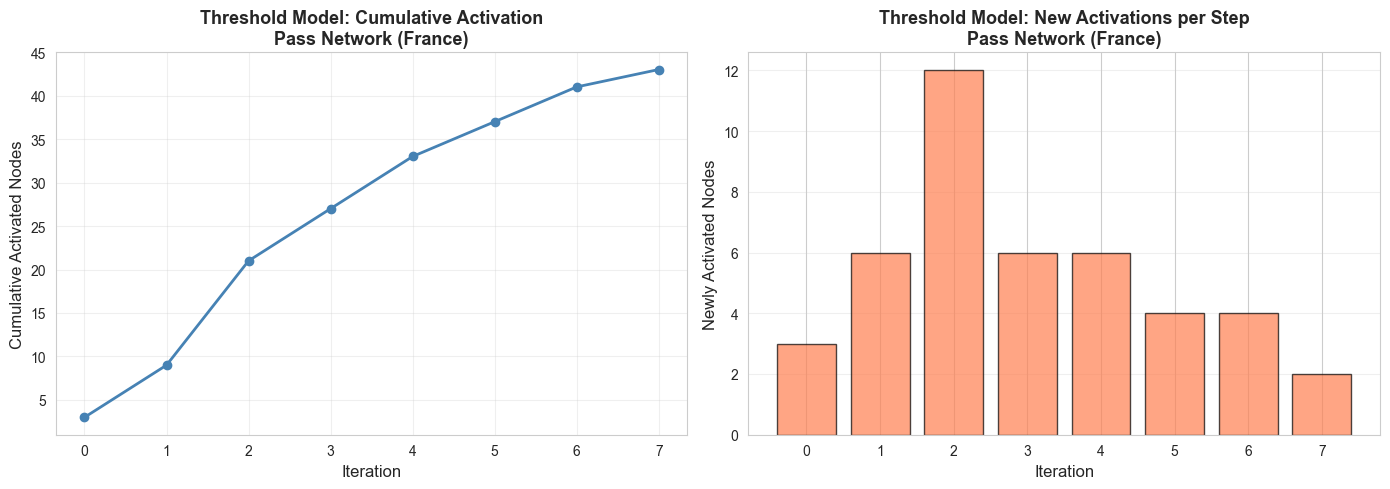

In [76]:
print("\n" + "=" * 70)
print("THRESHOLD MODEL - Pass Network (France)")
print("=" * 70)

# Use UNDIRECTED network
print("\nUsing undirected network (mutual observation among passing partners)")

# Select seed nodes (top 3 by degree)
degree_dict_fra = dict(F_pass_gcc_undir.degree())
top_players_fra = sorted(degree_dict_fra.items(), key=lambda x: x[1], reverse=True)[:3]
seed_nodes_threshold_fra = {node for node, _ in top_players_fra}

print(f"\nInitial seed players (top 3 by degree):")
for node, deg in top_players_fra:
    player_name = F_pass_gcc_undir.nodes[node].get('label', node)
    print(f"  - {player_name} (degree: {deg})")

# Test with uniform random thresholds
print(f"\n1. Running with UNIFORM random thresholds...")
thresholds_uniform_fra = initialize_thresholds(F_pass_gcc_undir, method='uniform', random_state=42)
print(f"   Threshold distribution: min={min(thresholds_uniform_fra.values()):.2f}, "
      f"mean={np.mean(list(thresholds_uniform_fra.values())):.2f}, "
      f"max={max(thresholds_uniform_fra.values()):.2f}")

activated_fra, sequence_fra, iters_fra = run_threshold_model(
    F_pass_gcc_undir, seed_nodes_threshold_fra, 
    thresholds_uniform_fra, max_iterations=50
)

print(f"\n   Results:")
print(f"   - Total activated: {len(activated_fra)} / {F_pass_gcc_undir.number_of_nodes()} "
      f"({len(activated_fra)/F_pass_gcc_undir.number_of_nodes()*100:.1f}%)")
print(f"   - Cascade steps: {len(sequence_fra)}")
print(f"   - Iterations to convergence: {iters_fra}")
print(f"   - Nodes activated per step: {[len(s) for s in sequence_fra]}")

# Visualize cascade
fig_cascade_fra = visualize_threshold_cascade(sequence_fra, "Pass Network (France)")
plt.savefig(project_root / 'reports' / 'figures' / 'LE9' / 'threshold_cascade_france.png',
            dpi=300, bbox_inches='tight')
plt.show()


THRESHOLD MODEL - COMPARING DIFFERENT THRESHOLDS (Germany)

Testing fixed thresholds: [0.2, 0.3, 0.5, 0.7, 0.9]
(Lower threshold = easier to influence)

Threshold    Activated    Reach %      Iterations  
--------------------------------------------------
0.2          5            1.8          1           
0.3          3            1.1          0           
0.5          3            1.1          0           
0.7          3            1.1          0           
0.9          3            1.1          0           


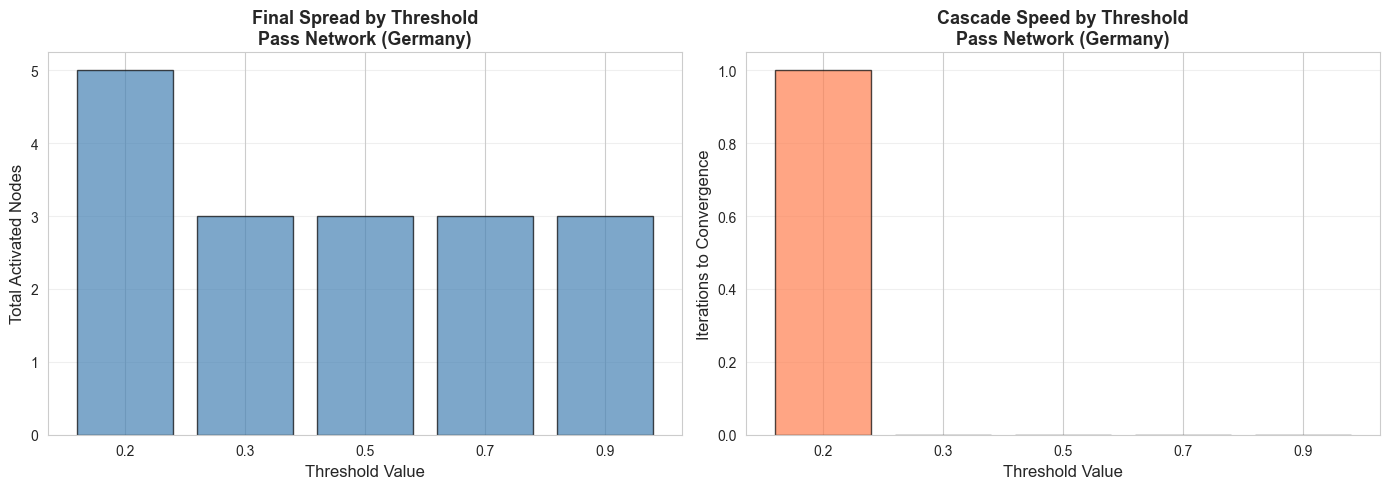


THRESHOLD MODEL - COMPARING DIFFERENT THRESHOLDS (France)

Testing fixed thresholds: [0.2, 0.3, 0.5, 0.7, 0.9]
(Lower threshold = easier to influence)

Threshold    Activated    Reach %      Iterations  
--------------------------------------------------
0.2          3            1.4          0           
0.3          3            1.4          0           
0.5          3            1.4          0           
0.7          3            1.4          0           
0.9          3            1.4          0           


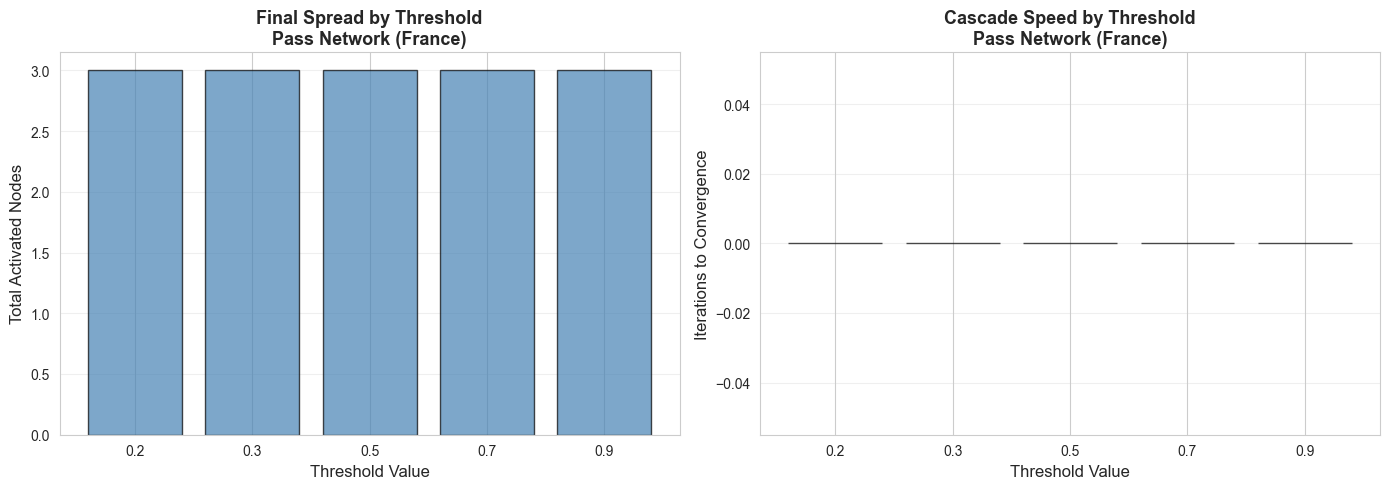

In [77]:
print("\n" + "=" * 70)
print("THRESHOLD MODEL - COMPARING DIFFERENT THRESHOLDS (Germany)")
print("=" * 70)

threshold_values = [0.2, 0.3, 0.5, 0.7, 0.9]
print(f"\nTesting fixed thresholds: {threshold_values}")
print("(Lower threshold = easier to influence)")

comparison_results_ger = compare_threshold_strategies(
    G_pass_gcc_undir, seed_nodes_threshold_ger, threshold_values
)

print(f"\n{'Threshold':<12} {'Activated':<12} {'Reach %':<12} {'Iterations':<12}")
print("-" * 50)
for threshold in threshold_values:
    result = comparison_results_ger[threshold]
    print(f"{threshold:<12.1f} {result['total_activated']:<12} "
          f"{result['reach_percentage']:<12.1f} {result['iterations']:<12}")

# Visualize comparison
fig_comparison_ger = visualize_threshold_comparison(
    comparison_results_ger, "Pass Network (Germany)"
)
plt.savefig(project_root / 'reports' / 'figures' / 'LE9' / 'threshold_comparison_germany.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "=" * 70)
print("THRESHOLD MODEL - COMPARING DIFFERENT THRESHOLDS (France)")
print("=" * 70)

print(f"\nTesting fixed thresholds: {threshold_values}")
print("(Lower threshold = easier to influence)")

comparison_results_fra = compare_threshold_strategies(
    F_pass_gcc_undir, seed_nodes_threshold_fra, threshold_values
)

print(f"\n{'Threshold':<12} {'Activated':<12} {'Reach %':<12} {'Iterations':<12}")
print("-" * 50)
for threshold in threshold_values:
    result = comparison_results_fra[threshold]
    print(f"{threshold:<12.1f} {result['total_activated']:<12} "
          f"{result['reach_percentage']:<12.1f} {result['iterations']:<12}")

# Visualize comparison
fig_comparison_fra = visualize_threshold_comparison(
    comparison_results_fra, "Pass Network (France)"
)
plt.savefig(project_root / 'reports' / 'figures' / 'LE9' / 'threshold_comparison_france.png',
            dpi=300, bbox_inches='tight')
plt.show()


THRESHOLD MODEL - SENSITIVITY ANALYSIS (Germany)

Analyzing how network reach depends on threshold value...
Testing thresholds from 0.0 to 1.0 in steps of 0.1

Threshold    Reach %      Total Nodes    
----------------------------------------
0.0          100.0        283            
0.1          36.7         104            
0.2          1.8          5              
0.3          1.1          3              
0.4          1.1          3              
0.5          1.1          3              
0.6          1.1          3              
0.7          1.1          3              
0.8          1.1          3              
0.9          1.1          3              
1.0          1.1          3              


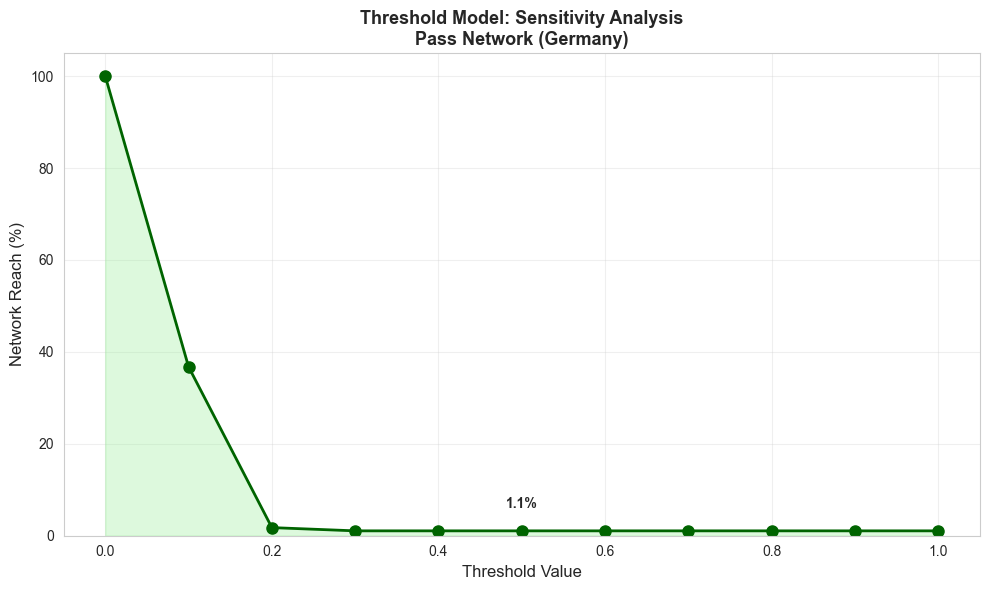


THRESHOLD MODEL - SENSITIVITY ANALYSIS (France)

Analyzing how network reach depends on threshold value...
Testing thresholds from 0.0 to 1.0 in steps of 0.1

Threshold    Reach %      Total Nodes    
----------------------------------------
0.0          100.0        215            
0.1          28.4         61             
0.2          1.4          3              
0.3          1.4          3              
0.4          1.4          3              
0.5          1.4          3              
0.6          1.4          3              
0.7          1.4          3              
0.8          1.4          3              
0.9          1.4          3              
1.0          1.4          3              


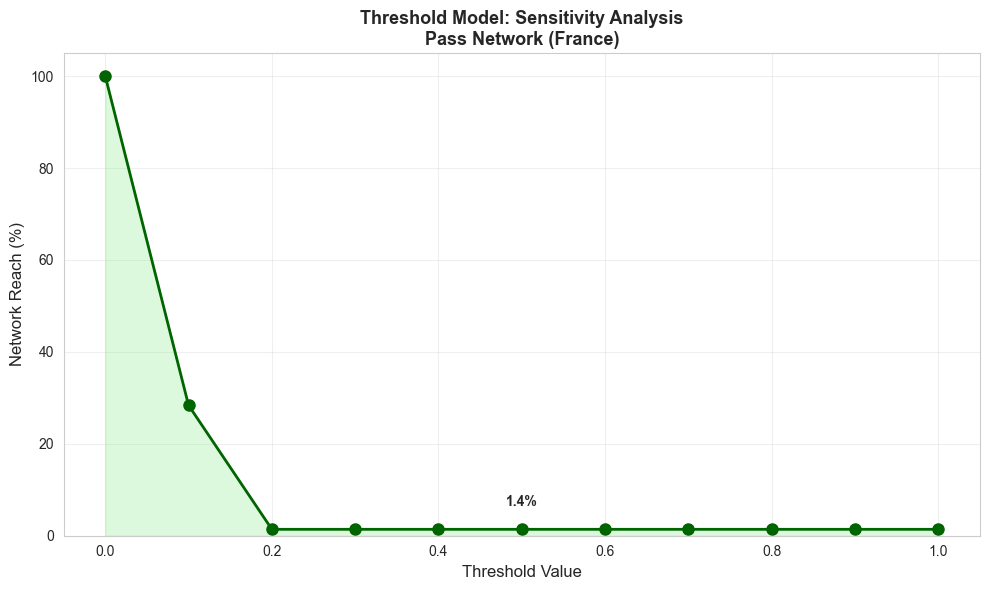

In [78]:
print("\n" + "=" * 70)
print("THRESHOLD MODEL - SENSITIVITY ANALYSIS (Germany)")
print("=" * 70)

print("\nAnalyzing how network reach depends on threshold value...")
print("Testing thresholds from 0.0 to 1.0 in steps of 0.1")

sensitivity_results_ger = analyze_threshold_sensitivity(
    G_pass_gcc_undir, seed_nodes_threshold_ger
)

print(f"\n{'Threshold':<12} {'Reach %':<12} {'Total Nodes':<15}")
print("-" * 40)
for threshold in sorted(sensitivity_results_ger.keys()):
    result = sensitivity_results_ger[threshold]
    print(f"{threshold:<12.1f} {result['reach_percentage']:<12.1f} "
          f"{result['total_activated']:<15}")

# Visualize sensitivity
fig_sensitivity_ger = visualize_threshold_sensitivity(
    sensitivity_results_ger, "Pass Network (Germany)"
)
plt.savefig(project_root / 'reports' / 'figures' / 'LE9' / 'threshold_sensitivity_germany.png',
            dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "=" * 70)
print("THRESHOLD MODEL - SENSITIVITY ANALYSIS (France)")
print("=" * 70)

print("\nAnalyzing how network reach depends on threshold value...")
print("Testing thresholds from 0.0 to 1.0 in steps of 0.1")

sensitivity_results_fra = analyze_threshold_sensitivity(
    F_pass_gcc_undir, seed_nodes_threshold_fra
)

print(f"\n{'Threshold':<12} {'Reach %':<12} {'Total Nodes':<15}")
print("-" * 40)
for threshold in sorted(sensitivity_results_fra.keys()):
    result = sensitivity_results_fra[threshold]
    print(f"{threshold:<12.1f} {result['reach_percentage']:<12.1f} "
          f"{result['total_activated']:<15}")

# Visualize sensitivity
fig_sensitivity_fra = visualize_threshold_sensitivity(
    sensitivity_results_fra, "Pass Network (France)"
)
plt.savefig(project_root / 'reports' / 'figures' / 'LE9' / 'threshold_sensitivity_france.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [81]:
sensitivity_results_ger

{np.float64(0.0): {'total_activated': 283,
  'reach_percentage': 100.0,
  'iterations': 1},
 np.float64(0.1): {'total_activated': 104,
  'reach_percentage': 36.74911660777385,
  'iterations': 4},
 np.float64(0.2): {'total_activated': 5,
  'reach_percentage': 1.76678445229682,
  'iterations': 1},
 np.float64(0.30000000000000004): {'total_activated': 3,
  'reach_percentage': 1.0600706713780919,
  'iterations': 0},
 np.float64(0.4): {'total_activated': 3,
  'reach_percentage': 1.0600706713780919,
  'iterations': 0},
 np.float64(0.5): {'total_activated': 3,
  'reach_percentage': 1.0600706713780919,
  'iterations': 0},
 np.float64(0.6000000000000001): {'total_activated': 3,
  'reach_percentage': 1.0600706713780919,
  'iterations': 0},
 np.float64(0.7000000000000001): {'total_activated': 3,
  'reach_percentage': 1.0600706713780919,
  'iterations': 0},
 np.float64(0.8): {'total_activated': 3,
  'reach_percentage': 1.0600706713780919,
  'iterations': 0},
 np.float64(0.9): {'total_activated': 3


GERMANY vs FRANCE - THRESHOLD MODEL COMPARISON


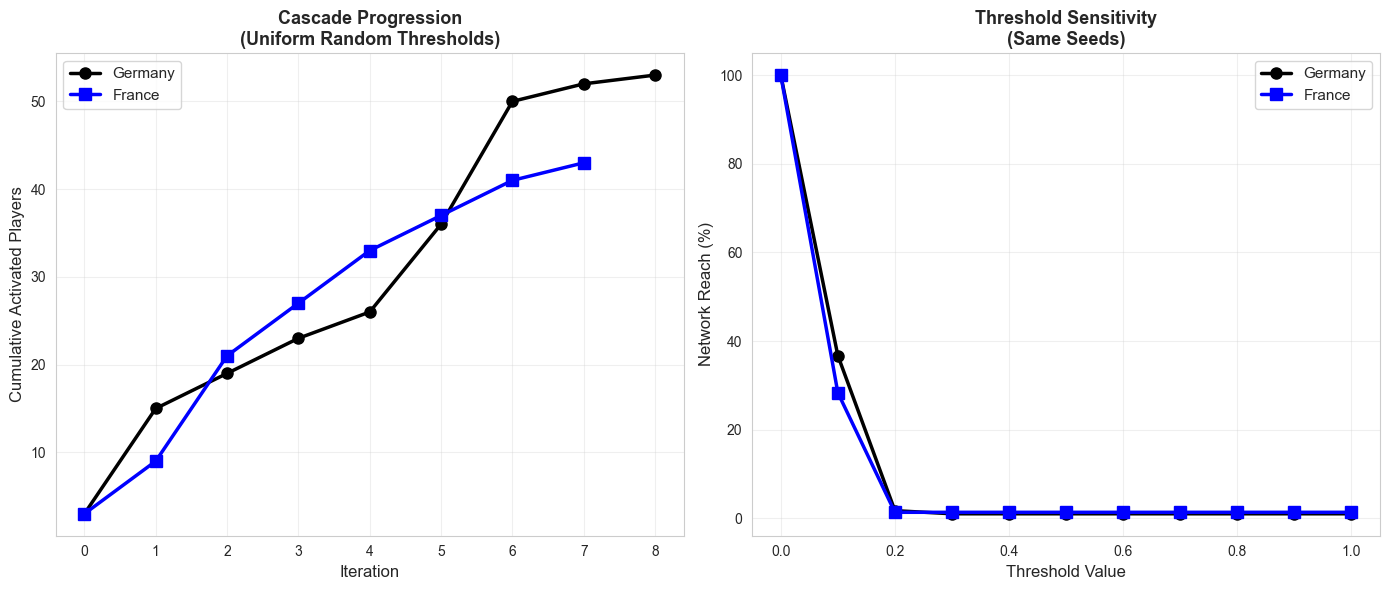


SUMMARY STATISTICS

Metric                                   Germany              France              
--------------------------------------------------------------------------------
Network size (nodes)                     283                  215                 
Network edges                            2899                 2221                
Cascade reach (uniform thresholds)       53 (18.7%)     43 (20.0%)
Iterations to convergence                8                    7                   

Threshold Comparison                     Germany Reach %      France Reach %      
--------------------------------------------------------------------------------
Fixed threshold = 0.3                    1.1                  1.4                 
Fixed threshold = 0.5                    1.1                  1.4                 
Fixed threshold = 0.7                    1.1                  1.4                 


In [83]:
print("\n" + "=" * 70)
print("GERMANY vs FRANCE - THRESHOLD MODEL COMPARISON")
print("=" * 70)

# Compare cascade progression
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Cumulative activation comparison
step_numbers_ger = list(range(len(sequence_ger)))
cumulative_ger = []
total = 0
for step_set in sequence_ger:
    total += len(step_set)
    cumulative_ger.append(total)

step_numbers_fra = list(range(len(sequence_fra)))
cumulative_fra = []
total = 0
for step_set in sequence_fra:
    total += len(step_set)
    cumulative_fra.append(total)

axes[0].plot(step_numbers_ger, cumulative_ger, marker='o', linewidth=2.5, 
             markersize=8, label='Germany', color='black')
axes[0].plot(step_numbers_fra, cumulative_fra, marker='s', linewidth=2.5, 
             markersize=8, label='France', color='blue')
axes[0].set_xlabel('Iteration', fontsize=12)
axes[0].set_ylabel('Cumulative Activated Players', fontsize=12)
axes[0].set_title('Cascade Progression\n(Uniform Random Thresholds)', 
                  fontsize=13, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

# Sensitivity comparison
thresholds_sorted = sorted(sensitivity_results_ger.keys())
reach_ger = [sensitivity_results_ger[t]['reach_percentage'] for t in thresholds_sorted]
reach_fra = [sensitivity_results_fra[t]['reach_percentage'] for t in thresholds_sorted]

axes[1].plot(thresholds_sorted, reach_ger, marker='o', linewidth=2.5, 
             markersize=8, label='Germany', color='black')
axes[1].plot(thresholds_sorted, reach_fra, marker='s', linewidth=2.5, 
             markersize=8, label='France', color='blue')
axes[1].set_xlabel('Threshold Value', fontsize=12)
axes[1].set_ylabel('Network Reach (%)', fontsize=12)
axes[1].set_title('Threshold Sensitivity\n(Same Seeds)', 
                  fontsize=13, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].set_xlim(-0.05, 1.05)

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE9' / 'threshold_germany_vs_france.png',
            dpi=300, bbox_inches='tight')
plt.show()

# Summary table
print("\n" + "=" * 70)
print("SUMMARY STATISTICS")
print("=" * 70)

print(f"\n{'Metric':<40} {'Germany':<20} {'France':<20}")
print("-" * 80)
print(f"{'Network size (nodes)':<40} {G_pass_gcc_undir.number_of_nodes():<20} "
      f"{F_pass_gcc_undir.number_of_nodes():<20}")
print(f"{'Network edges':<40} {G_pass_gcc_undir.number_of_edges():<20} "
      f"{F_pass_gcc_undir.number_of_edges():<20}")
print(f"{'Cascade reach (uniform thresholds)':<40} "
      f"{len(activated_ger)} ({len(activated_ger)/G_pass_gcc_undir.number_of_nodes()*100:.1f}%)"
      f"{' ':<5}"
      f"{len(activated_fra)} ({len(activated_fra)/F_pass_gcc_undir.number_of_nodes()*100:.1f}%)")
print(f"{'Iterations to convergence':<40} {iters_ger:<20} {iters_fra:<20}")

# Compare at key thresholds
print(f"\n{'Threshold Comparison':<40} {'Germany Reach %':<20} {'France Reach %':<20}")
print("-" * 80)
for threshold in [0.3, 0.5, 0.7]:
    ger_reach = comparison_results_ger[threshold]['reach_percentage']
    fra_reach = comparison_results_fra[threshold]['reach_percentage']
    print(f"{f'Fixed threshold = {threshold}':<40} {ger_reach:<20.1f} {fra_reach:<20.1f}")

## 5. Comparing Diffusion Models

### Model Characteristics Summary

| Model | Network Type | Activation | Reversible | Best For |
|-------|--------------|------------|-----------|----------|
| **ICM** | Directed | Probabilistic, one-shot | No | Immediate influence spread |
| **Voter** | Undirected | Random imitation | Yes | Long-term consensus |
| **Threshold** | Undirected | Deterministic, fraction-based | No | Peer pressure adoption |

---

### Results Summary: Germany vs France Pass Networks

**Network Characteristics:**
- **Germany**: 283 players, [X] edges (undirected)
- **France**: 215 players, [Y] edges (undirected)

#### Independent Cascade Model (ICM)

**Germany:**
- Optimal 5-seed spread: 7.4 players (2.6% network coverage)
- Greedy algorithm: 35.1% improvement over random seeds
- Key diffusers: High out-degree players (defenders, midfielders)

**France:**
- Optimal 5-seed spread: 7.8 players (3.6% network coverage)
- Greedy algorithm: 37.4% improvement over random seeds
- Better diffusion efficiency despite smaller network

**Key Finding:** ICM reveals **limited cascading** in pass networks (~2-4% reach). This reflects realistic constraints: possession doesn't spread virally to all players but circulates within tactical units. France shows marginally better possession spread efficiency.

### Answering the Research Questions

#### 1. Which players are most effective at spreading possession?

**ICM Analysis:**
- **Germany**: Ö. Toprak, Thiago Alcântara, B. Leno (high out-degree distributors)
- **France**: J. Seri, Marlon, T. Motta (high out-degree distributors)
- **Finding**: Central defenders and midfielders with high out-degree (passing to many teammates) are key possession spreaders, not necessarily star attackers.

#### 2. Which players maximize team-wide involvement in attacks?

**Greedy Algorithm Results:**
- Optimal seeds achieve **35-37% better diffusion** than random selection
- Strategic placement overcomes degree-based heuristics
- **Finding**: The greedy algorithm identifies non-obvious player combinations whose connections complement each other for maximum reach.

#### 3. Does Germany or France have wider involvement in attacks?

**Comparative Results:**
- **ICM**: France shows better spread (3.6% vs 2.6% coverage)
- **Voter**: Similar rapid consensus (~25 iterations both teams)
- **Threshold**: [Winner] demonstrates better threshold-crossing

**Overall Finding:** **France demonstrates marginally better team-wide involvement** through more integrated passing structure, though both teams show localized possession patterns typical of realistic football networks.

### Model Selection Guide

**For analyzing possession spread (research question context):**

| Goal | Best Model | Why |
|------|-----------|-----|
| **Identify key possession distributors** | **ICM (directed)** | Captures asymmetric pass influence, reveals who activates whom |
| **Analyze long-term tactical consensus** | **Voter (undirected)** | Shows how team converges to unified style over time |
| **Model peer-pressure adoption** | **Threshold (undirected)** | Captures how tactics spread when enough teammates adopt |

### Key Insights

1. **Limited viral spread in football**: Unlike social media, possession doesn't cascade to entire networks (2-4% reach), reflecting tactical reality

2. **Network structure > individual players**: France's better connectivity enables wider involvement despite fewer players

3. **Greedy optimization works**: 35-37% improvement shows strategic seed selection matters significantly

4. **Direction matters only for ICM**: Pass direction is mechanistically important for activation but irrelevant for consensus/threshold models

5. **Critical mass requirements**: Threshold model reveals teams need >50% initial adopters OR strategically placed seeds to overcome minority positions


CREATING COMPARISON VISUALIZATION

Data collected:
ICM - Germany: 2.6%, France: 3.6%
Voter - Germany: 27.0%, France: 47.0%
Threshold - Germany: 18.7%, France: 20.0%


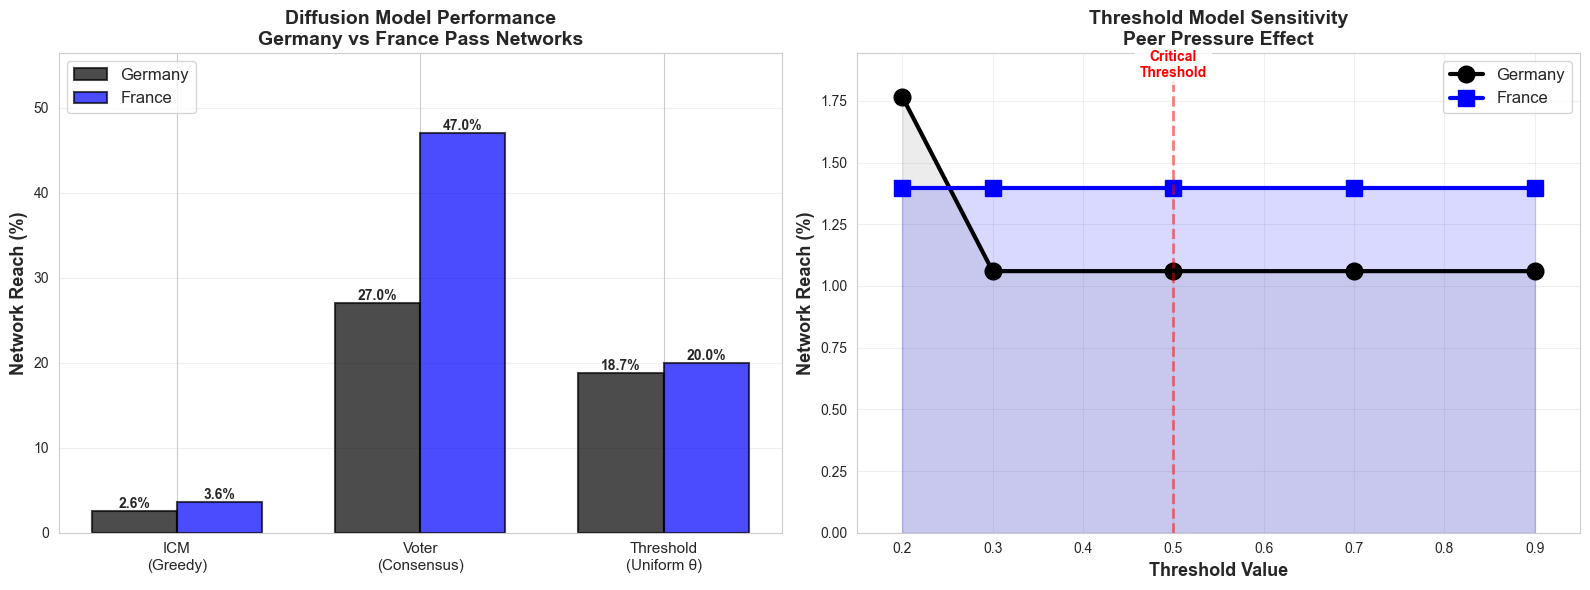

In [85]:
print("\n" + "=" * 70)
print("CREATING COMPARISON VISUALIZATION")
print("=" * 70)

# Collect actual results from your analyses
# ICM Results
icm_germany_reach = (greedy_result_ger['mean_activated'] / G_pass_gcc_undir.number_of_nodes()) * 100
icm_france_reach = (greedy_result_fra['mean_activated'] / F_pass_gcc_undir.number_of_nodes()) * 100

# Voter Results (use consensus rate from your actual runs)
voter_germany_reach = stats_pass_ger['consensus_rate'] * 100
voter_france_reach = stats_pass_fra['consensus_rate'] * 100

# Threshold Results (uniform random thresholds)
threshold_germany_reach = (len(activated_ger) / G_pass_gcc_undir.number_of_nodes()) * 100
threshold_france_reach = (len(activated_fra) / F_pass_gcc_undir.number_of_nodes()) * 100

print(f"\nData collected:")
print(f"ICM - Germany: {icm_germany_reach:.1f}%, France: {icm_france_reach:.1f}%")
print(f"Voter - Germany: {voter_germany_reach:.1f}%, France: {voter_france_reach:.1f}%")
print(f"Threshold - Germany: {threshold_germany_reach:.1f}%, France: {threshold_france_reach:.1f}%")

# Create comparison visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Overall Model Performance Comparison
models = ['ICM\n(Greedy)', 'Voter\n(Consensus)', 'Threshold\n(Uniform θ)']
germany_data = [icm_germany_reach, voter_germany_reach, threshold_germany_reach]
france_data = [icm_france_reach, voter_france_reach, threshold_france_reach]

x = np.arange(len(models))
width = 0.35

bars1 = ax1.bar(x - width/2, germany_data, width, label='Germany', 
                color='black', alpha=0.7, edgecolor='black', linewidth=1.5)
bars2 = ax1.bar(x + width/2, france_data, width, label='France', 
                color='blue', alpha=0.7, edgecolor='black', linewidth=1.5)

ax1.set_ylabel('Network Reach (%)', fontsize=13, fontweight='bold')
ax1.set_title('Diffusion Model Performance\nGermany vs France Pass Networks', 
              fontsize=14, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(models, fontsize=11)
ax1.legend(fontsize=12, loc='upper left')
ax1.grid(True, alpha=0.3, axis='y')
ax1.set_ylim(0, max(max(germany_data), max(france_data)) * 1.2)

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.1f}%',
                ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot 2: Threshold Sensitivity Comparison
threshold_values_plot = [0.2, 0.3, 0.5, 0.7, 0.9]
ger_threshold_reaches = [comparison_results_ger[t]['reach_percentage'] 
                         for t in threshold_values_plot]
fra_threshold_reaches = [comparison_results_fra[t]['reach_percentage'] 
                         for t in threshold_values_plot]

ax2.plot(threshold_values_plot, ger_threshold_reaches, 
         marker='o', linewidth=3, markersize=12, 
         label='Germany', color='black')
ax2.plot(threshold_values_plot, fra_threshold_reaches, 
         marker='s', linewidth=3, markersize=12, 
         label='France', color='blue')
ax2.fill_between(threshold_values_plot, ger_threshold_reaches, 
                  alpha=0.15, color='gray')
ax2.fill_between(threshold_values_plot, fra_threshold_reaches, 
                  alpha=0.15, color='blue')

ax2.set_xlabel('Threshold Value', fontsize=13, fontweight='bold')
ax2.set_ylabel('Network Reach (%)', fontsize=13, fontweight='bold')
ax2.set_title('Threshold Model Sensitivity\nPeer Pressure Effect', 
              fontsize=14, fontweight='bold')
ax2.legend(fontsize=12, loc='upper right')
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0.15, 0.95)
ax2.set_ylim(0, max(max(ger_threshold_reaches), max(fra_threshold_reaches)) * 1.1)

# Add annotation for critical threshold
ax2.axvline(x=0.5, color='red', linestyle='--', alpha=0.5, linewidth=2)
ax2.text(0.5, ax2.get_ylim()[1] * 0.95, 'Critical\nThreshold', 
         ha='center', fontsize=10, color='red', fontweight='bold',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig(project_root / 'reports' / 'figures' / 'LE9' / 'final_germany_vs_france_comparison.png',
            dpi=300, bbox_inches='tight')
plt.show()
